In [14]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import cmcrameri.cm as cmc


In [15]:

def parse_comsol_data(filepath):
    """
    Parse COMSOL data file and return organized DataFrame.
    
    Parameters:
    -----------
    filepath : str
        Path to the COMSOL data file
        
    Returns:
    --------
    pd.DataFrame
        DataFrame with columns for coordinates, physical parameters, U_in, and Sb_option
    """
    
    with open(filepath, 'r') as file:
        lines = file.readlines()
    
    # Find the header line with column names
    header_line = None
    data_start = None
    
    for i, line in enumerate(lines):
        if line.startswith('% r;z;'):
            header_line = line.strip()
            data_start = i + 1
            break
    
    if header_line is None:
        raise ValueError("Could not find header line starting with '% r;z;'")
    
    # Parse the header to extract column information
    header_line = header_line[2:]  # Remove '% ' prefix
    
    # Split the header and extract parameter names and conditions
    columns = header_line.split(';')
    
    # Parse column names to extract parameter names, U_in values, and Sb_option values
    parsed_columns = []
    
    for col in columns:
        if '@' in col:
            # Extract parameter name and conditions
            parts = col.split('@')
            param_name = parts[0].strip()
            conditions = parts[1].strip()
            
            # Extract U_in value
            u_in_match = re.search(r'U_in=([0-9E.-]+)', conditions)
            u_in = float(u_in_match.group(1)) if u_in_match else None
            
            # Extract Sb_option value
            sb_match = re.search(r'Sb_option=([0-9]+)', conditions)
            sb_option = int(sb_match.group(1)) if sb_match else None
            
            parsed_columns.append({
                'original_name': col,
                'param_name': param_name,
                'u_in': u_in,
                'sb_option': sb_option
            })
        else:
            # Coordinate columns (r, z)
            parsed_columns.append({
                'original_name': col,
                'param_name': col,
                'u_in': None,
                'sb_option': None
            })
    
    # Read the data
    data_lines = lines[data_start:]
    
    # Parse data rows
    data_rows = []
    for line in data_lines:
        if line.strip():  # Skip empty lines
            values = [float(x) for x in line.strip().split(';')]
            data_rows.append(values)
    
    # Create DataFrame with original column structure
    df_raw = pd.DataFrame(data_rows, columns=[col['original_name'] for col in parsed_columns])
    
    # Reorganize data by grouping parameters by U_in and Sb_option
    organized_data = []
    
    # Get coordinate columns (r, z)
    coord_cols = [col for col in parsed_columns if col['u_in'] is None]
    
    # Get unique combinations of U_in and Sb_option
    param_cols = [col for col in parsed_columns if col['u_in'] is not None]
    unique_conditions = set((col['u_in'], col['sb_option']) for col in param_cols)
    
    for u_in, sb_option in unique_conditions:
        # Get all parameter columns for this condition
        condition_cols = [col for col in param_cols 
                         if col['u_in'] == u_in and col['sb_option'] == sb_option]
        
        # For each row in the original data
        for idx, row in df_raw.iterrows():
            # Start with coordinates
            row_data = {'r': row[coord_cols[0]['original_name']], 
                       'z': row[coord_cols[1]['original_name']]}
            
            # Add condition identifiers
            row_data['U_in'] = u_in
            row_data['Sb_option'] = sb_option
            
            # Add all parameters for this condition
            for col in condition_cols:
                param_name = col['param_name']
                # Clean up parameter names (remove units and extra info)
                clean_param_name = param_name.split('(')[0].strip()
                row_data[clean_param_name] = row[col['original_name']]
            
            organized_data.append(row_data)
    
    # Create the final organized DataFrame
    df_organized = pd.DataFrame(organized_data)
    
    # Sort by U_in, Sb_option, and spatial coordinates
    df_organized = df_organized.sort_values(['U_in', 'Sb_option', 'r', 'z']).reset_index(drop=True)
    
    return df_organized
def calculate_excess_pressure(df):
    """
    Calculate excess pressure as linproj_r - rho_e*g*depth.
    
    Parameters:
    -----------
    df : pd.DataFrame
        The organized dataframe from parse_comsol_data
        
    Returns:
    --------
    pd.DataFrame
        DataFrame with added P_excess column
    """
    df_copy = df.copy()
    
    # Constants
    rho_e = 2700  # kg/m³
    g = 9.81      # m/s²
    
    # Calculate excess pressure
    # P_excess = linproj_r - rho_e * g * depth
    # Note: z is negative (z=0 at surface, z=-5000 at 5km depth)
    # So depth = -z (depth is positive)
    depth = -df_copy['z']  # Convert negative z to positive depth
    df_copy['P_excess'] = df_copy['linproj_r'] - (rho_e * g * depth)# +2.5e6+1e5)  # Adding 2.5 MPa offset for lithostatic pressure at surface
    
    print(f"Debug: z range: {df_copy['z'].min()} to {df_copy['z'].max()}")
    print(f"Debug: depth range: {depth.min()} to {depth.max()}")
    print(f"Debug: linproj_r range: {df_copy['linproj_r'].min()} to {df_copy['linproj_r'].max()}")
    print(f"Debug: P_excess range: {df_copy['P_excess'].min()} to {df_copy['P_excess'].max()}")
    
    return df_copy


In [16]:
def get_colormap(colormap):
    """
    Try to get a colormap from cmcrameri.cm, else fallback to matplotlib colormaps.
    """
    import matplotlib.pyplot as plt
    import cmcrameri.cm as cmc
    try:
        return getattr(cmc, colormap)
    except AttributeError:
        try:
            return plt.get_cmap(colormap)
        except Exception:
            print(f"Colormap '{colormap}' not found in cmcrameri or matplotlib. Using 'viridis'.")
            return plt.cm.viridis

In [17]:

# File path
# filepath_sb_0 = '../../data/3_outgassing_models/conduit_wall_Sb0_colima.txt'

filepath_xg_4 = '../../data/supplimentary/Xg_thres/conduit_wall_Xg_thresh_04.txt'


filepath_xg_3 = '../../data/supplimentary/Xg_thres/conduit_wall_Xg_thresh_03.txt'


filepath_xg_5 = '../../data/supplimentary/Xg_thres/conduit_wall_Xg_thresh_05.txt'


filepath_xg_6 = '../../data/supplimentary/Xg_thres/conduit_wall_Xg_thresh_06.txt'



filepath_xg_7 = '../../data/supplimentary/Xg_thres/conduit_wall_Xg_thresh_07.txt'


filepath_xg_8 = '../../data/supplimentary/Xg_thres/conduit_wall_Xg_thresh_08.txt'

# Load and organize the data
print("Loading COMSOL conduit data...")
df_xg_3 = parse_comsol_data(filepath_xg_3)
df_xg_4 = parse_comsol_data(filepath_xg_4)
df_xg_5 = parse_comsol_data(filepath_xg_5)
df_xg_6 = parse_comsol_data(filepath_xg_6)
df_xg_7 = parse_comsol_data(filepath_xg_7)
df_xg_8 = parse_comsol_data(filepath_xg_8)

# Combine dataframes
df = pd.concat([df_xg_3, df_xg_4, df_xg_5,df_xg_6, df_xg_7, df_xg_8], ignore_index=True)

# Display basic information about the dataset
print(f"\nDataset loaded successfully!")
print(f"Shape: {df.shape}")
print(f"Columns: {list(df.columns)}")

# Show unique values for key grouping variables

# Display first few rows
print(f"\nFirst 5 rows:")
print(df.head())

# Display summary statistics
print(f"\nSummary statistics:")
print(df.describe())

# Group by U_in and Sb_option to show data organization
print(f"\nData organization by U_in and Sb_option:")
grouped = df.groupby(['U_in', 'Sb_option']).size()
print(grouped)

# Save to CSV for easy access
#output_file = '.conduit_data_organized.csv'
#df.to_csv(output_file, index=False)
#print(f"\nData saved to: {output_file}")


# Create the main grid plot with variables as columns and sb_options as rows
selected_vars = ['Xc_nocap', 'Xg', 'rho_b', 'mu_m']
#plot_variables_vs_depth_grid(df, variables=selected_vars, colormap='batlow')

# 

Loading COMSOL conduit data...

Dataset loaded successfully!
Shape: (1552776, 21)
Columns: ['r', 'z', 'U_in', 'Sb_option', 'Xc_nocap', 'Xc', 'Sb', 'Xg', 'spf.mu*spf.sr', 'rho_b', 'rho_m', 'Xm', 'T', 'linproj_r', 'mu_m', 'nu_b_inf', 'nu_c', 'mu_mbc', 'u_av', 'Cw', 'Xg_thres']

First 5 rows:
      r       z     U_in  Sb_option  Xc_nocap   Xc   Sb   Xg  spf.mu*spf.sr  \
0  15.0 -3000.0  0.00001          6       0.4  0.4  1.0  0.0        0.40361   
1  15.0 -2999.6  0.00001          6       0.4  0.4  1.0  0.0        0.40362   
2  15.0 -2999.3  0.00001          6       0.4  0.4  1.0  0.0        0.40362   
3  15.0 -2998.9  0.00001          6       0.4  0.4  1.0  0.0        0.40361   
4  15.0 -2998.6  0.00001          6       0.4  0.4  1.0  0.0        0.40361   

    rho_b  ...   Xm       T   linproj_r     mu_m  nu_b_inf    nu_c    mu_mbc  \
0  2700.0  ...  0.6  1223.0  67489000.0  32961.0       1.0  4.5918  151350.0   
1  2700.0  ...  0.6  1223.0  67479000.0  32961.0       1.0  4.5918  151350

In [18]:
df

,r,z,U_in,Sb_option,Xc_nocap,Xc,Sb,Xg,spf.mu*spf.sr,rho_b,...,Xm,T,linproj_r,mu_m,nu_b_inf,nu_c,mu_mbc,u_av,Cw,Xg_thres
0,15.0,-3000.00000,0.00001,6,0.4,0.4,1.00000,0.0,4.036100e-01,2700.00,...,0.6,1223.0,67489000.0,32961.0,1.000000,4.5918,151350.0,0.00001,0.030000,0.3
1,15.0,-2999.60000,0.00001,6,0.4,0.4,1.00000,0.0,4.036200e-01,2700.00,...,0.6,1223.0,67479000.0,32961.0,1.000000,4.5918,151350.0,0.00001,0.030000,0.3
2,15.0,-2999.30000,0.00001,6,0.4,0.4,1.00000,0.0,4.036200e-01,2700.00,...,0.6,1223.0,67470000.0,32961.0,1.000000,4.5918,151350.0,0.00001,0.030000,0.3
3,15.0,-2998.90000,0.00001,6,0.4,0.4,1.00000,0.0,4.036100e-01,2700.00,...,0.6,1223.0,67460000.0,32961.0,1.000000,4.5918,151350.0,0.00001,0.030000,0.3
4,15.0,-2998.60000,0.00001,6,0.4,0.4,1.00000,0.0,4.036100e-01,2700.00,...,0.6,1223.0,67451000.0,32961.0,1.000000,4.5918,151350.0,0.00001,0.030000,0.3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1552771,15.0,-1.42310,0.31623,6,0.4,0.4,0.42251,0.8,1.346000e+06,543.75,...,0.6,1223.0,2627200.0,12315000.0,0.068399,4.5919,3867800.0,1.41280,0.002583,0.8
1552772,15.0,-1.06710,0.31623,6,0.4,0.4,0.41411,0.8,1.343300e+06,543.68,...,0.6,1223.0,2573700.0,12367000.0,0.068399,4.5919,3884100.0,1.41140,0.002576,0.8
1552773,15.0,-0.71128,0.31623,6,0.4,0.4,0.40571,0.8,1.338700e+06,543.61,...,0.6,1223.0,2525400.0,12416000.0,0.068399,4.5919,3899400.0,1.41010,0.002569,0.8
1552774,15.0,-0.35558,0.31623,6,0.4,0.4,0.39721,0.8,1.330900e+06,543.53,...,0.6,1223.0,2484700.0,12462000.0,0.068399,4.5919,3914100.0,1.40910,0.002563,0.8


In [19]:
df['Xg_thres'].unique()

array([0.3, 0.4, 0.5, 0.6, 0.7, 0.8])

In [20]:
# #Create the specific conduit analysis plot
# print(f"\nCreating conduit analysis plot...")
# #plot_conduit_analysis(df, colormap='gnuplot')

# print(print(df[(df['U_in'] == 0.1) & (df['z'] == -3000)]))
# #import pdb; pdb.set_trace()
# plot_conduit_analysis_fig2(df, colormap='batlow', figsize=(7, 4), save_plot=True)




In [21]:
# ...existing code...

import matplotlib.patches as mpatches


def plot_conduit_analysis_fig2_presentation(
    df,
    colormap='batlow',
    figsize=(20, 14),
    save_plot=True,
    fixed_sb_option=6
):
    """
    Plot conduit analysis variables while varying Xg_thres.

    Colours represent Xg_thres using a LINEAR Batlow colour map
    normalized from Xg_thres = 0 to Xg_thres = 0.8.

    Sb_option is held fixed.

    Parameters
    ----------
    df : pd.DataFrame
        Organized dataframe from parse_comsol_data.

    colormap : str
        Name of cmcrameri colormap.
        Default = 'batlow'.

    figsize : tuple
        Figure size.

    save_plot : bool
        Whether to save the figure.

    fixed_sb_option : int
        Sb_option to hold constant while varying Xg_thres.
        Default = 6.
    """

    import numpy as np
    import matplotlib.pyplot as plt
    import matplotlib as mpl
    from matplotlib.ticker import MaxNLocator
    from matplotlib.colors import Normalize

    # ------------------------------------------------------------------
    # MATPLOTLIB FORMATTING
    # ------------------------------------------------------------------

    mpl.rcParams.update({
        'font.family': 'sans-serif',
        'font.sans-serif': [
            'Helvetica',
            'Arial',
            'Liberation Sans',
            'DejaVu Sans'
        ],
        'font.size': 11,
        'axes.labelsize': 11,
        'axes.titlesize': 11,
        'xtick.labelsize': 9.5,
        'ytick.labelsize': 9.5,
        'legend.fontsize': 11,
        'figure.titlesize': 11
    })

    print("axes.labelsize:", mpl.rcParams['axes.labelsize'])
    print("axes.titlesize:", mpl.rcParams['axes.titlesize'])
    print("xtick.labelsize:", mpl.rcParams['xtick.labelsize'])
    print("ytick.labelsize:", mpl.rcParams['ytick.labelsize'])
    print("legend.fontsize:", mpl.rcParams['legend.fontsize'])
    print("figure.titlesize:", mpl.rcParams['figure.titlesize'])
    print("font.size:", mpl.rcParams['font.size'])

    # ------------------------------------------------------------------
    # CALCULATE EXCESS PRESSURE
    # ------------------------------------------------------------------

    df_analysis = calculate_excess_pressure(df).copy()

    # ------------------------------------------------------------------
    # VARIABLES TO PLOT
    # ------------------------------------------------------------------

    variables = {
        'Xg': r'$X_g$',
        'P_excess': r'$\Delta P$ (MPa)',
        'spf.mu*spf.sr': r'$\tau$ (MPa)',
    }

    n_vars = len(variables)

    # ------------------------------------------------------------------
    # CHECK REQUIRED COLUMN
    # ------------------------------------------------------------------

    if 'Xg_thres' not in df_analysis.columns:
        raise KeyError(
            "Column 'Xg_thres' was not found in df_analysis. "
            "Check the exact column name in your dataframe."
        )

    # ------------------------------------------------------------------
    # HOLD Sb_option FIXED
    # ------------------------------------------------------------------

    df_analysis = df_analysis[
        df_analysis['Sb_option'] == fixed_sb_option
    ].copy()

    if df_analysis.empty:
        raise ValueError(
            f"No data found for Sb_option = {fixed_sb_option}"
        )

    # ------------------------------------------------------------------
    # Xg_thres OPTIONS
    # ------------------------------------------------------------------
    # Use all threshold values in the range 0 --> 0.8
    # ------------------------------------------------------------------

    xg_thres_options = sorted(
        df_analysis.loc[
            (df_analysis['Xg_thres'] >= 0.0) &
            (df_analysis['Xg_thres'] <= 0.8),
            'Xg_thres'
        ]
        .dropna()
        .unique()
    )

    if len(xg_thres_options) == 0:
        raise ValueError(
            "No Xg_thres values between 0 and 0.8 were found."
        )

    print("\nXg_thres values plotted:")
    print(xg_thres_options)

    # ------------------------------------------------------------------
    # BATLOW COLORMAP
    # ------------------------------------------------------------------

    cmap = get_colormap(colormap)

    # IMPORTANT:
    # Fixed linear normalization between 0 and 0.8.
    #
    # Therefore:
    # Xg_thres = 0.0 --> cmap(0.00)
    # Xg_thres = 0.2 --> cmap(0.25)
    # Xg_thres = 0.4 --> cmap(0.50)
    # Xg_thres = 0.6 --> cmap(0.75)
    # Xg_thres = 0.8 --> cmap(1.00)
    #
    xg_norm = Normalize(
        vmin=0.3,
        vmax=0.8
    )

    xg_thres_to_color = {
        xg_thres: cmap(xg_norm(xg_thres))
        for xg_thres in xg_thres_options
    }

    # ------------------------------------------------------------------
    # VELOCITIES
    # ------------------------------------------------------------------

    velocities = sorted(
        df_analysis['U_in']
        .dropna()
        .unique()
    )

    # Two velocities displayed in depth-profile panels
    selected_velocities = [
        0.001,
        0.1
    ]

    # ------------------------------------------------------------------
    # CREATE FIGURE
    # ------------------------------------------------------------------

    fig = plt.figure(
        figsize=figsize
    )

    # Top panel + six bottom panels
    #
    # Bottom:
    #
    # Xg   Pexcess   stress     gap     Xg   Pexcess   stress
    #
    # velocity = 0.001                    velocity = 0.1
    #

    gs = fig.add_gridspec(
        2,
        n_vars * 2 + 1,
        height_ratios=[0.65, 1],
        width_ratios=[1] * n_vars + [0.30] + [1] * n_vars,
        hspace=1.4,
        wspace=0.25
    )

    # ------------------------------------------------------------------
    # TOP AXIS
    # ------------------------------------------------------------------

    top_ax = fig.add_subplot(
        gs[0, :]
    )

    # ------------------------------------------------------------------
    # BOTTOM AXES
    # ------------------------------------------------------------------

    bottom_axes = []

    # Left set
    for i in range(3):

        ax = fig.add_subplot(
            gs[1, i]
        )

        bottom_axes.append(ax)

    # gs[1, 3] is deliberately empty

    # Right set
    for i in range(4, 7):

        ax = fig.add_subplot(
            gs[1, i]
        )

        bottom_axes.append(ax)

    main_axes = [
        top_ax,
        bottom_axes
    ]

    # ==================================================================
    # BOTTOM PANELS
    # ==================================================================
    #
    # Loop over Xg_thres FIRST.
    #
    # This means every Xg_thres produces one line in each panel.
    # Colour corresponds ONLY to Xg_thres.
    #
    # ==================================================================

    for xg_thres in xg_thres_options:

        # --------------------------------------------------------------
        # Filter current threshold
        # --------------------------------------------------------------

        df_threshold = df_analysis[
            np.isclose(
                df_analysis['Xg_thres'],
                xg_thres
            )
        ].copy()

        # Colour from fixed 0 --> 0.8 Batlow normalization
        color = xg_thres_to_color[xg_thres]

        # --------------------------------------------------------------
        # Loop over the two selected velocities
        # --------------------------------------------------------------

        for n, velocity in enumerate(selected_velocities):

            # n = 0 --> axes 0,1,2
            # n = 1 --> axes 3,4,5
            constant_row = n * n_vars

            # ----------------------------------------------------------
            # Current velocity
            # ----------------------------------------------------------

            df_velocity = df_threshold[
                np.isclose(
                    df_threshold['U_in'],
                    velocity
                )
            ].copy()

            # ----------------------------------------------------------
            # Variables
            # ----------------------------------------------------------

            for j, (var, var_name) in enumerate(variables.items()):

                ax = main_axes[1][
                    constant_row + j
                ]

                if (
                    not df_velocity.empty
                    and var in df_velocity.columns
                ):

                    # Sort by depth
                    data_subset = (
                        df_velocity
                        .sort_values('z')
                        .copy()
                    )

                    depth = data_subset['z']

                    # --------------------------------------------------
                    # Units
                    # --------------------------------------------------

                    if var in [
                        'spf.mu*spf.sr',
                        'P_excess'
                    ]:

                        plot_vals = (
                            data_subset[var]
                            / 1e6
                        )

                    elif var == 'Cw':

                        plot_vals = (
                            data_subset[var]
                            * 100
                        )

                    else:

                        plot_vals = (
                            data_subset[var]
                        )

                    # --------------------------------------------------
                    # Plot
                    # --------------------------------------------------

                    ax.plot(
                        plot_vals,
                        depth / 1e3,
                        color=color,
                        linewidth=2,
                        alpha=0.90
                    )

    # ==================================================================
    # FORMAT BOTTOM PANELS
    # ==================================================================

    for n, velocity in enumerate(selected_velocities):

        constant_row = n * n_vars

        for j, (var, var_name) in enumerate(variables.items()):

            ax = main_axes[1][
                constant_row + j
            ]

            # ----------------------------------------------------------
            # LOG SCALE
            # ----------------------------------------------------------

            if var in [
                'mu_mbc',
                'mu_m',
                'nu_c'
            ]:

                ax.set_xscale('log')

            if ax.get_xscale() != 'log':

                ax.xaxis.set_major_locator(
                    MaxNLocator(
                        nbins=4,
                        prune=None
                    )
                )

            # ----------------------------------------------------------
            # CUSTOM TICKS
            # ----------------------------------------------------------

            if var == 'Cw':

                ax.set_xticks(
                    [0, 1, 2, 3]
                )

                ax.set_xticklabels(
                    ['0', '1', '2', '3']
                )

            # elif var == 'spf.mu*spf.sr':

            #     if n == 1:

            #         ticks = [
            #             0,
            #             0.15
            #         ]

            #         ax.set_xticks(ticks)

            #         ax.set_xticklabels([
            #             r'0',
            #             r'$0.15$'
            #         ])

            #     else:

            #         ticks = [
            #             0,
            #             2
            #         ]

            #         ax.set_xticks(ticks)

            #         ax.set_xticklabels([
            #             r'0',
            #             r'$2$'
            #         ])

            # elif var == 'Xg':

            #     ticks = [
            #         0,
            #         0.3
            #     ]

            #     ax.set_xticks(ticks)

            #     ax.set_xticklabels([
            #         r'0',
            #         r'$0.3$'
            #     ])

            elif var == 'nu_c':

                ticks = [
                    1,
                    1e2,
                    1e4
                ]

                ax.set_xticks(ticks)

                ax.set_xticklabels([
                    r'$1$',
                    r'$10^{2}$',
                    r'$10^{4}$'
                ])

            # ----------------------------------------------------------
            # AXIS LABELS
            # ----------------------------------------------------------

            ax.set_xlabel(
                var_name
            )

            ax.tick_params(
                axis='x',
                labelbottom=True
            )

            # Show depth label only on first plot in each 3-panel set
            if j == 0:
                if ax == main_axes[1][0]:
                    ax.set_ylabel(
                        "Depth (km)",
                        labelpad=2
                    )
                # ax.set_ylabel(
                #     "Depth (km)",
                #     labelpad=2
                # )

            else:

                ax.set_ylabel("")

                ax.set_yticklabels([])

            # ----------------------------------------------------------
            # GRID
            # ----------------------------------------------------------

            ax.grid(
                True,
                alpha=0.3
            )

    # ==================================================================
    # VELOCITY LABELS UNDER BOTTOM PANELS
    # ==================================================================

    main_axes[1][1].set_title(
        'Ascent Velocity = 0.001 m/s',
        y=-0.22,
        color='blue'
    )

    main_axes[1][4].set_title(
        'Ascent Velocity = 0.1 m/s',
        y=-0.22,
        color='red'
    )

    # ==================================================================
    # BOTTOM AXIS STYLE
    # ==================================================================

    for j, ax in enumerate(main_axes[1]):

        # Put x ticks and x labels on top
        ax.xaxis.set_ticks_position(
            'top'
        )

        ax.xaxis.set_label_position(
            'top'
        )

        # Remove bottom/right spines
        ax.spines[
            'bottom'
        ].set_visible(False)

        ax.spines[
            'right'
        ].set_visible(False)

        # Raise x-axis title
        ax.xaxis.set_label_coords(
            0.5,
            1.22
        )

        # Tick spacing
        ax.tick_params(
            axis='x',
            which='both',
            pad=0
        )

        ax.xaxis.labelpad = 0

    mpl.rcParams[
        'xtick.major.pad'
    ] = 0

    # ==================================================================
    # TOP PANEL
    #
    # Inlet excess pressure vs ascent velocity.
    #
    # One curve for each Xg_thres.
    # Same Batlow colour used as bottom panels.
    #
    # ==================================================================

    for xg_thres in xg_thres_options:

        df_threshold = df_analysis[
            np.isclose(
                df_analysis['Xg_thres'],
                xg_thres
            )
        ].copy()

        p_excess_deepest = []
        velocities_plot = []

        # --------------------------------------------------------------
        # Go through all velocities
        # --------------------------------------------------------------

        for velocity in velocities:

            df_vel = df_threshold[
                np.isclose(
                    df_threshold['U_in'],
                    velocity
                )
            ].copy()

            if not df_vel.empty:

                # Deepest point
                deepest_idx = (
                    df_vel['z']
                    .idxmin()
                )

                deepest_z = df_vel.loc[
                    deepest_idx,
                    'z'
                ]

                deepest_p_excess = df_vel.loc[
                    deepest_idx,
                    'P_excess'
                ]

                p_excess_deepest.append(
                    deepest_p_excess
                    / 1e6
                )

                velocities_plot.append(
                    velocity
                )

        # --------------------------------------------------------------
        # Plot current Xg threshold curve
        # --------------------------------------------------------------

        if len(velocities_plot) > 0:

            color = (
                xg_thres_to_color[
                    xg_thres
                ]
            )

            top_ax.semilogx(
                velocities_plot,
                p_excess_deepest,
                color=color,
                alpha=0.95,
                linewidth=2.5
            )

    # ==================================================================
    # TOP PANEL FORMATTING
    # ==================================================================

    top_ax.set_ylabel(
        r'Inlet $\Delta P$ (MPa)',
        labelpad=1
    )

    top_ax.set_xlabel(
        'Inlet Velocity (m/s)',
        labelpad=1
    )

    top_ax.set_title(
        r'Effect of $X_{g,\mathrm{thres}}$ '
        r'on Inlet Overpressure'
    )

    top_ax.grid(
        True,
        alpha=0.3
    )

    top_ax.tick_params(
        axis='x',
        pad=1
    )

    top_ax.tick_params(
        axis='y',
        pad=1
    )

    # --------------------------------------------------------------
    # Reference velocities
    # --------------------------------------------------------------

    top_ax.axvline(
        0.1,
        color='red',
        linestyle='--',
        linewidth=1,
        alpha=0.7
    )

    top_ax.axvline(
        0.001,
        color='blue',
        linestyle='--',
        linewidth=1,
        alpha=0.7
    )

    # --------------------------------------------------------------
    # Limits
    # --------------------------------------------------------------

    # top_ax.set_ylim(
    #     -15,
    #     15
    # )

    top_ax.set_xlim([
        5e-5,
        1.2
    ])

    # --------------------------------------------------------------
    # Remove top/right spines
    # --------------------------------------------------------------

    top_ax.spines[
        'top'
    ].set_visible(False)

    top_ax.spines[
        'right'
    ].set_visible(False)

    # ==================================================================
    # Xg_thres COLOURBAR
    # ==================================================================

    sm = mpl.cm.ScalarMappable(
        norm=xg_norm,
        cmap=cmap
    )

    sm.set_array([])

    # Colourbar shared by all panels
    cbar = fig.colorbar(
        sm,
        ax=[top_ax],
        orientation='vertical',
        fraction=0.022,
        pad=0.025,
        aspect=30
    )

    cbar.set_label(
        r'$X_{g,\mathrm{thres}}$',
        rotation=90,
        labelpad=1
    )

    # Fixed linear colourbar ticks
    cbar.set_ticks([
        0.4,
        0.6,
        0.8
    ])

    cbar.set_ticklabels([
        '0.4',
        '0.6',
        '0.8'
    ])

    # ==================================================================
    # PANEL LABELS A, B, C, ...
    # ==================================================================

    import string

    labels = list(
        string.ascii_uppercase
    )

    label_idx = 0

    # Top panel = A
    top_ax.text(
        0.98,
        0.02,
        labels[label_idx],
        transform=top_ax.transAxes,
        fontsize=10,
        fontweight='bold',
        va='bottom',
        ha='right'
    )

    label_idx += 1

    # Bottom panels = B, C, ...
    for ax in main_axes[1]:

        ax.text(
            0.98,
            0.02,
            labels[label_idx],
            transform=ax.transAxes,
            fontsize=10,
            fontweight='bold',
            va='bottom',
            ha='right'
        )

        label_idx += 1

    # ==================================================================
    # SAVE
    # ==================================================================

    # if save_plot:

    #     fig.savefig(
    #         '../../output_plots/3/'
    #         'figure2_conduit_analysis_Colima_'
    #         'Xg_thres_comparison_flow_only.pdf',
    #         dpi=300,
    #         bbox_inches='tight'
    #     )

    #     fig.savefig(
    #         '../../output_plots/3/'
    #         'figure2_conduit_analysis_Colima_'
    #         'Xg_thres_comparison_flow_only.svg',
    #         dpi=300,
    #         bbox_inches='tight'
    #     )

    return fig


Creating conduit analysis plot...
            r       z  U_in  Sb_option  Xc_nocap   Xc   Sb   Xg  \
225040   15.0 -3000.0   0.1          6       0.4  0.4  1.0  0.0   
483836   15.0 -3000.0   0.1          6       0.4  0.4  1.0  0.0   
742632   15.0 -3000.0   0.1          6       0.4  0.4  1.0  0.0   
1001428  15.0 -3000.0   0.1          6       0.4  0.4  1.0  0.0   
1260224  15.0 -3000.0   0.1          6       0.4  0.4  1.0  0.0   
1519020  15.0 -3000.0   0.1          6       0.4  0.4  1.0  0.0   

         spf.mu*spf.sr   rho_b  ...   Xm       T   linproj_r     mu_m  \
225040          4036.1  2700.0  ...  0.6  1223.0  81301000.0  32961.0   
483836          4036.1  2700.0  ...  0.6  1223.0  78728000.0  32961.0   
742632          4036.1  2700.0  ...  0.6  1223.0  76545000.0  32961.0   
1001428         4036.1  2700.0  ...  0.6  1223.0  74830000.0  32961.0   
1260224         4036.1  2700.0  ...  0.6  1223.0  73603000.0  32961.0   
1519020         4036.1  2700.0  ...  0.6  1223.0  7282900

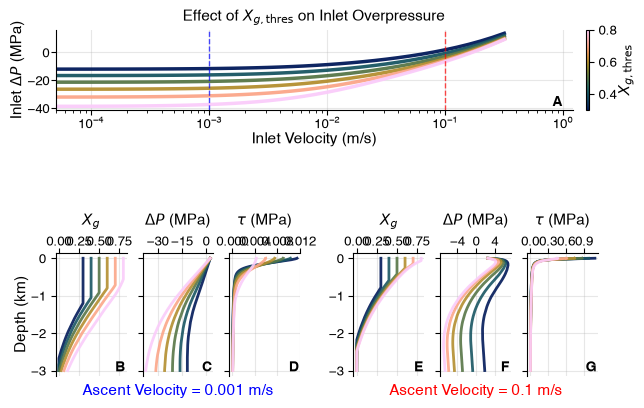

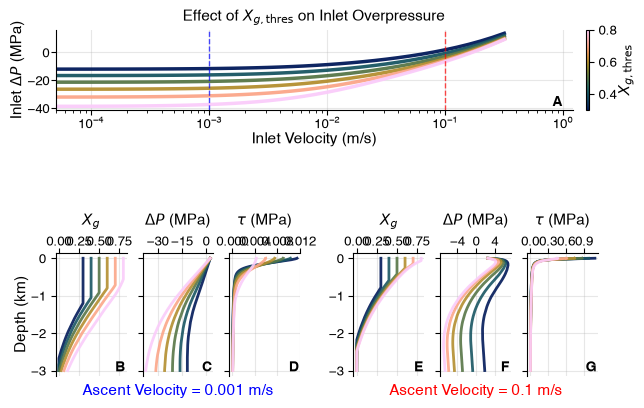

In [22]:
#Create the specific conduit analysis plot
print(f"\nCreating conduit analysis plot...")
#plot_conduit_analysis(df, colormap='gnuplot')

print(print(df[(df['U_in'] == 0.1) & (df['z'] == -3000)]))
#import pdb; pdb.set_trace()
plot_conduit_analysis_fig2_presentation(df, colormap='batlow', figsize=(7, 4.5), save_plot=True)




In [23]:

def parse_comsol_edge_data(filepath,var_names):
    with open(filepath, 'r') as file:
        lines = file.readlines()

    # Find the header line with column names
    header_line = None
    data_start = None

    for i, line in enumerate(lines):
        if line.startswith('% r;z;'):
            header_line = line.strip()
            data_start = i + 1
            break

    if header_line is None:
        raise ValueError("Could not find header line starting with '% r;z;'")

    # Parse the header to extract column information
    header_line = header_line[2:]  # Remove '% ' prefix

    #print(f"Header line: {header_line}")
    # Split the header and extract parameter names and conditions
    columns = header_line.split(';')

    # Parse column names to extract parameter names, U_in values, and Sb_option values
    parsed_columns = {}

    df = pd.DataFrame(index=range(len(columns)),columns=['param_name']+var_names)

    for i, col in enumerate(columns):
        #print('col:' + col)
        if '@' in col:
            # Extract parameter name and conditions
            parts = col.split('@')
            param_name = parts[0].strip()
            conditions = parts[1].strip()
            vars=conditions.split(',')

            
            
            df.at[i, 'param_name'] = param_name


            for k,var in enumerate(vars):
                if '=' in var:
                    key, value = var.split('=')
                    key = key.strip()
                    value = value.strip()
                    #print(f"Condition: {key} = {float(value)}")
                    df.at[i, var_names[k]] = float(value)
                else:
                    #print(f"Condition: {var_names[k]} : {var}")
                    df.at[i, var_names[k]] = var
        else:
            # Coordinate columns (r, z)
            df.at[i, 'param_name'] = col.strip()
            for k,var in enumerate(var_names):
                df.at[i, var_names[k]] = None
            
        
    data_lines = lines[data_start:]
    # # Parse data rows
    data_rows = []
    for line in data_lines:
        if line.strip():  # Skip empty lines
            values = [float(x) for x in line.strip().split(';')]
            data_rows.append(values)

    # # Create DataFrame with original column structure
    df_raw = pd.DataFrame(data_rows, columns=['r','z']+columns[2:])

    # Create new dataframe that will be the final export
    # params = df['param_name'].dropna().unique()
    #print(params.tolist()+var_names)

    # # Read the data

    params = df['param_name'].dropna().unique()

    params_list = params
    params_list = params_list[2:]
    print(params.tolist()+var_names)
    columns = params.tolist()+var_names

    # find unique values of each parameter
    df_vars = df.drop('param_name',axis=1)
    df_unique_vars= df_vars.drop_duplicates(keep='first').dropna(how='all')

    print('Number of rows in new dataframe')
    n_rows = df_raw.shape[0]*np.shape(df_unique_vars)[0]
    print(n_rows)

    output_df = pd.DataFrame(index=range(n_rows),columns=columns)
    print('Number of unique variables:' ,np.shape(df_unique_vars))


    param = params_list[0]
    for param in params_list:
        row_idx = 0
        for idx, row in df_unique_vars.iterrows():
            
            
                print('loop start')
                #print(f"Processing param: {param}")
                print(f"Processing param: {param}")
                row['param_name'] = param

                # find which rows in df match this row 
                mask = (df[row.index] == row.values).all(axis=1)
                matching_rows = df[mask]
                for raw_idx, raw_row in df_raw.iterrows():
                    value=raw_row.iloc[matching_rows.index.to_list()[0]]
                    
                    r = raw_row['r']
                    z = raw_row['z']

                    output_df.at[row_idx, 'r'] = r
                    output_df.at[row_idx, 'z'] = z
                    
                    for var_name in var_names:
                        print(row_idx,var_name)
                        output_df.at[row_idx, var_name] = row[var_name]  
                    output_df.at[row_idx, param] = value 
                    row_idx += 1

    new_names = []
    for i,name in enumerate(output_df.columns):
        
        new_names.append(name.split(' ')[0])

    output_df.columns = new_names

    return output_df






In [24]:
ge_fp_sb_0 = r'../../data/supplimentary/Xg_thres/ground_edge_xg_thres.txt'





In [25]:

filepath = ge_fp_sb_0
var_names = ['U_in', 'Xg_thres', 'Sb_option', 'param_1', 'param_def']
df_ge_test = parse_comsol_edge_data(filepath,var_names)
df_ge = df_ge_test
# filepath = ge_fp_sb_4
# df_ge_test4 = parse_comsol_edge_data(filepath,var_names)
# var_names = ['U_in', 'Sb_option', 'tau_Xc', 'param_1','param_def']
# filepath = ge_fp_sb_6
# df_ge_test6 = parse_comsol_edge_data(filepath,var_names)
# df_ge_test = pd.concat([df_ge_test0, df_ge_test4, df_ge_test6], ignore_index=True)

# df_ge = pd.concat([df_ge_test0, df_ge_test4, df_ge_test6], ignore_index=True)
# #df_ge = pd.concat([df_ge_Sb0, df_ge_Sb4, df_ge_Sb6], ignore_index=True)

['r', 'z', 'u2 (m)', 'v2 (m)', 'w2 (m)', 'solid.RotrZ (rad)', 'U_in', 'Xg_thres', 'Sb_option', 'param_1', 'param_def']
Number of rows in new dataframe
72864
Number of unique variables: (828, 5)
loop start
Processing param: u2 (m)
0 U_in
0 Xg_thres
0 Sb_option
0 param_1
0 param_def
1 U_in
1 Xg_thres
1 Sb_option
1 param_1
1 param_def
2 U_in
2 Xg_thres
2 Sb_option
2 param_1
2 param_def
3 U_in
3 Xg_thres
3 Sb_option
3 param_1
3 param_def
4 U_in
4 Xg_thres
4 Sb_option
4 param_1
4 param_def
5 U_in
5 Xg_thres
5 Sb_option
5 param_1
5 param_def
6 U_in
6 Xg_thres
6 Sb_option
6 param_1
6 param_def
7 U_in
7 Xg_thres
7 Sb_option
7 param_1
7 param_def
8 U_in
8 Xg_thres
8 Sb_option
8 param_1
8 param_def
9 U_in
9 Xg_thres
9 Sb_option
9 param_1
9 param_def
10 U_in
10 Xg_thres
10 Sb_option
10 param_1
10 param_def
11 U_in
11 Xg_thres
11 Sb_option
11 param_1
11 param_def
12 U_in
12 Xg_thres
12 Sb_option
12 param_1
12 param_def
13 U_in
13 Xg_thres
13 Sb_option
13 param_1
13 param_def
14 U_in
14 Xg_thres
14

In [26]:
df_ge

,r,z,u2,v2,w2,solid.RotrZ,U_in,Xg_thres,Sb_option,param_1,param_def
0,15.0,0.0,0.072769,0.0,0.16806,0.032624,0.31623,0.3,6.0,1.0,0.0
1,15.183,0.0,0.071953,0.0,0.16279,0.024372,0.31623,0.3,6.0,1.0,0.0
2,15.385,0.0,0.070905,0.0,0.15829,0.020548,0.31623,0.3,6.0,1.0,0.0
3,15.608,0.0,0.069772,0.0,0.154,0.0181,0.31623,0.3,6.0,1.0,0.0
4,15.855,0.0,0.068546,0.0,0.14978,0.016264,0.31623,0.3,6.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
72859,2368.5,-876.46,-0.003524,0.0,-0.000135,-0.000001,0.00001,0.8,6.0,1.0,2.0
72860,2552.1,-952.98,-0.003281,0.0,-0.00001,-0.000001,0.00001,0.8,6.0,1.0,2.0
72861,2756.2,-1038.0,-0.002994,0.0,0.000121,-0.000001,0.00001,0.8,6.0,1.0,2.0
72862,2992.2,-1136.3,-0.002643,0.0,0.000256,-0.000001,0.00001,0.8,6.0,1.0,2.0


In [27]:
df_ge['Xg_thres'].unique()

array([0.3, 0.4, 0.5, 0.6, 0.7, 0.8], dtype=object)

Debug: z range: -3000.0 to 0.0
Debug: depth range: -0.0 to 3000.0
Debug: linproj_r range: 2453400.0 to 93109000.0
Debug: P_excess range: -38681000.0 to 13648594.799999997

Xg_thres values plotted: [np.float64(0.3), np.float64(0.4), np.float64(0.5), np.float64(0.6), np.float64(0.7), np.float64(0.8)]
Maximum common velocity: 0.31623
Maximum common velocity used for all Xg_thres curves: 0.31623 m/s


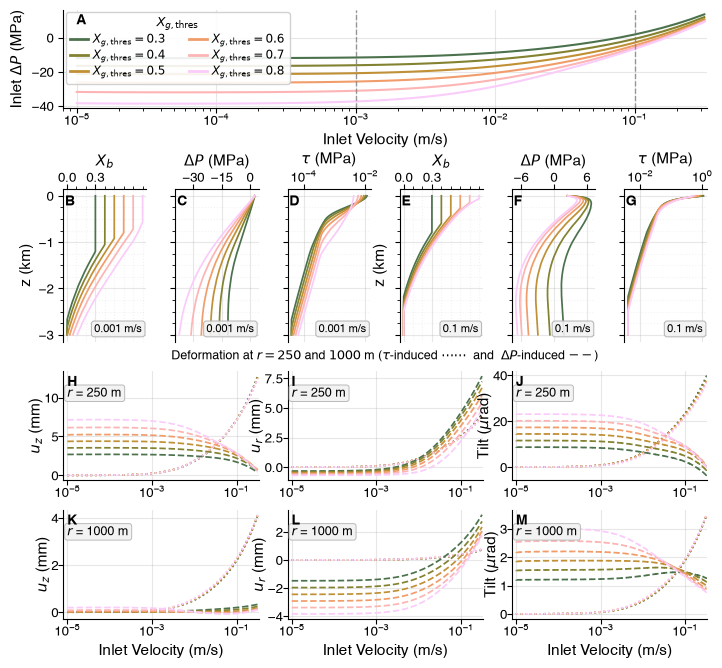

In [30]:
def plot_combined_conduit_and_ground_deformation(
    df,
    df_ge,
    selected_velocities=(0.001, 0.1),
    figsize=(18, 13),
    save_plot=False,
    fixed_sb_option=6,
    colormap='batlow',
    output_prefix='../../output_plots/3/figure2_combined_conduit_ground_deformation_Xgthres'
):
    import matplotlib.pyplot as plt
    import matplotlib as mpl
    import numpy as np
    import pandas as pd
    import string

    from matplotlib.ticker import MaxNLocator, MultipleLocator
    from matplotlib.colors import Normalize
    from matplotlib.lines import Line2D

    # ============================================================
    # MATPLOTLIB FORMATTING
    # ============================================================

    mpl.rcParams.update({
        'font.family': 'sans-serif',
        'font.sans-serif': [
            'Helvetica',
            'Arial',
            'Liberation Sans',
            'DejaVu Sans'
        ],
        'font.size': 11,
        'axes.labelsize': 11,
        'axes.titlesize': 11,
        'xtick.labelsize': 9.5,
        'ytick.labelsize': 9.5,
        'legend.fontsize': 9,
    })

    # ============================================================
    # PREPARE CONDUIT DATA
    # ============================================================

    df_analysis = calculate_excess_pressure(df).copy()
    df_ge_plot = df_ge.copy()

    # ------------------------------------------------------------
    # Check required columns
    # ------------------------------------------------------------

    required_conduit = [
        'Sb_option',
        'Xg_thres',
        'U_in',
        'z'
    ]

    required_deformation = [
        'Sb_option',
        'Xg_thres',
        'U_in',
        'r'
    ]

    for col in required_conduit:
        if col not in df_analysis.columns:
            raise KeyError(
                f"Column '{col}' not found in conduit dataframe."
            )

    for col in required_deformation:
        if col not in df_ge_plot.columns:
            raise KeyError(
                f"Column '{col}' not found in deformation dataframe."
            )

    # ============================================================
    # HOLD Sb_option FIXED
    # ============================================================

    df_analysis = df_analysis[
        df_analysis['Sb_option'] == fixed_sb_option
    ].copy()

    df_ge_plot = df_ge_plot[
        df_ge_plot['Sb_option'] == fixed_sb_option
    ].copy()

    if df_analysis.empty:
        raise ValueError(
            f'No conduit data found for Sb_option = {fixed_sb_option}.'
        )

    if df_ge_plot.empty:
        raise ValueError(
            f'No deformation data found for Sb_option = {fixed_sb_option}.'
        )

    # ============================================================
    # Xg_thres VALUES
    #
    # Only thresholds between 0 and 0.8 are retained.
    #
    # Use values that are present in BOTH conduit and deformation
    # datasets so every colour corresponds to the same experiment.
    # ============================================================

    conduit_xg = np.array(
        sorted(
            df_analysis.loc[
                (df_analysis['Xg_thres'] >= 0.0) &
                (df_analysis['Xg_thres'] <= 0.8),
                'Xg_thres'
            ]
            .dropna()
            .unique()
        ),
        dtype=float
    )

    deformation_xg = np.array(
        sorted(
            df_ge_plot.loc[
                (df_ge_plot['Xg_thres'] >= 0.0) &
                (df_ge_plot['Xg_thres'] <= 0.8),
                'Xg_thres'
            ]
            .dropna()
            .unique()
        ),
        dtype=float
    )

    # Use approximate matching because these may be floats
    xg_thres_options = []

    for xg in conduit_xg:

        if np.any(
            np.isclose(
                deformation_xg,
                xg,
                rtol=1e-7,
                atol=1e-10
            )
        ):
            xg_thres_options.append(xg)

    xg_thres_options = sorted(
        xg_thres_options
    )

    if len(xg_thres_options) == 0:
        raise ValueError(
            'No common Xg_thres values between 0 and 0.8 '
            'were found in df and df_ge.'
        )

    print(
        '\nXg_thres values plotted:',
        xg_thres_options
    )

    # ============================================================
    # BATLOW COLOURS
    # ============================================================

    cmap = get_colormap(colormap)

    # Fixed linear normalization:
    #
    # Xg_thres = 0.0 -> beginning of Batlow
    # Xg_thres = 0.8 -> end of Batlow
    #
    xg_norm = Normalize(
        vmin=0.0,
        vmax=0.8
    )

    xg_to_color = {
        xg: cmap(
            xg_norm(xg)
        )
        for xg in xg_thres_options
    }

    # ============================================================
    # VELOCITY RANGE
    # ============================================================
    #
    # Find the largest velocity for which the different thresholds
    # can be compared consistently.
    #
    # We determine the maximum available velocity for each Xg_thres
    # in both datasets, then take the smallest of those maxima.
    # ============================================================

    maximum_velocities = []

    for xg_thres in xg_thres_options:

        conduit_subset = df_analysis[
            np.isclose(
                df_analysis['Xg_thres'],
                xg_thres
            )
        ]

        deformation_subset = df_ge_plot[
            np.isclose(
                df_ge_plot['Xg_thres'],
                xg_thres
            )
        ]

        conduit_velocities = (
            conduit_subset['U_in']
            .dropna()
        )

        deformation_velocities = (
            deformation_subset['U_in']
            .dropna()
        )

        if not conduit_velocities.empty:
            maximum_velocities.append(
                conduit_velocities.max()
            )

        if not deformation_velocities.empty:
            maximum_velocities.append(
                deformation_velocities.max()
            )

    if len(maximum_velocities) == 0:
        raise ValueError(
            'No velocity data available.'
        )

    max_velocity_common = min(
        maximum_velocities
    )

    # ------------------------------------------------------------
    # Restrict both datasets to common velocity range
    # ------------------------------------------------------------

    df_analysis = df_analysis[
        df_analysis['U_in']
        <= max_velocity_common
    ].copy()

    df_ge_plot = df_ge_plot[
        df_ge_plot['U_in']
        <= max_velocity_common
    ].copy()

    # ------------------------------------------------------------
    # Minimum positive velocity
    # ------------------------------------------------------------

    positive_velocities = pd.concat([
        df_analysis['U_in'],
        df_ge_plot['U_in']
    ]).dropna()

    positive_velocities = positive_velocities[
        positive_velocities > 0
    ]

    if positive_velocities.empty:
        raise ValueError(
            'No positive inlet velocities found.'
        )

    min_velocity = (
        positive_velocities.min()
    )

    print(
        'Maximum common velocity:',
        max_velocity_common
    )

    # ============================================================
    # PLOT DEFINITIONS
    # ============================================================

    variables = {
        'Xg': r'$X_b$',
        'P_excess': r'$\Delta P$ (MPa)',
        'spf.mu*spf.sr': r'$\tau$ (MPa)',
    }

    # ------------------------------------------------------------
    # Ground deformation distances
    # ------------------------------------------------------------

    distances = [
        250,
        1000
    ]

    # ------------------------------------------------------------
    # Ground deformation variables
    # ------------------------------------------------------------

    deformation_cols = [
        (
            'w2',
            r'$u_z$ (mm)'
        ),
        (
            'u2',
            r'$u_r$ (mm)'
        ),
        (
            'solid.RotrZ',
            r'Tilt ($\mu$rad)'
        ),
    ]

    # ============================================================
    # FIGURE
    # ============================================================

    fig = plt.figure(
        figsize=figsize
    )

    gs = fig.add_gridspec(
        nrows=5,
        ncols=6,
        height_ratios=[
            0.9,   # inlet pressure
            0.2,   # spacer
            1.4,   # conduit profiles
            1.0,   # deformation at 250 m
            1.0,   # deformation at 1000 m
        ],
        hspace=0.3,
        wspace=0.35
    )

    # ============================================================
    # A. INLET OVERPRESSURE
    # ============================================================

    ax_top = fig.add_subplot(
        gs[0, :]
    )

    for xg_thres in xg_thres_options:

        df_xg = df_analysis[
            np.isclose(
                df_analysis['Xg_thres'],
                xg_thres
            )
        ].copy()

        vel_plot = []
        p_plot = []

        for velocity in sorted(
            df_xg['U_in']
            .dropna()
            .unique()
        ):

            df_vel = df_xg[
                np.isclose(
                    df_xg['U_in'],
                    velocity
                )
            ]

            if df_vel.empty:
                continue

            # Deepest conduit point
            deepest_idx = (
                df_vel['z']
                .idxmin()
            )

            vel_plot.append(
                velocity
            )

            p_plot.append(
                df_vel.loc[
                    deepest_idx,
                    'P_excess'
                ] / 1e6
            )

        if len(vel_plot) == 0:
            continue

        ax_top.semilogx(
            vel_plot,
            p_plot,
            color=xg_to_color[xg_thres],
            linewidth=1.5
        )

    # ------------------------------------------------------------
    # Mark selected conduit-profile velocities
    # ------------------------------------------------------------

    for velocity in selected_velocities:

        ax_top.axvline(
            velocity,
            color='0.45',
            linestyle='--',
            linewidth=1,
            alpha=0.7
        )

    # ------------------------------------------------------------
    # Top axis formatting
    # ------------------------------------------------------------

    ax_top.set_xlim(
        min_velocity * 0.8,
        max_velocity_common * 1.05
    )

    ax_top.set_xlabel(
        'Inlet Velocity (m/s)'
    )

    ax_top.set_ylabel(
        r'Inlet $\Delta P$ (MPa)'
    )

    ax_top.grid(
        True,
        alpha=0.3
    )

    ax_top.spines[
        'top'
    ].set_visible(False)

    ax_top.spines[
        'right'
    ].set_visible(False)

    # ============================================================
    # Xg_thres LEGEND
    # ============================================================
    #
    # Standard discrete legend rather than a colourbar.
    #
    # Colours are still determined by the continuous linear Batlow
    # normalization from 0 to 0.8.
    # ============================================================

    xg_legend_handles = []

    for xg_thres in xg_thres_options:

        handle = Line2D(
            [0],
            [0],
            color=xg_to_color[xg_thres],
            linewidth=2,
            linestyle='-',
            label=rf'$X_{{g,\mathrm{{thres}}}} = {xg_thres:g}$'
        )

        xg_legend_handles.append(
            handle
        )

    ax_top.legend(
        handles=xg_legend_handles,
        loc='upper left',
        fontsize=8.5,
        frameon=True,
        framealpha=0.9,
        borderpad=0.4,
        labelspacing=0.25,
        handlelength=1.5,
        handletextpad=0.4,
        borderaxespad=0.2,
        title=r'$X_{g,\mathrm{thres}}$',
        title_fontsize=9,
        ncol=2
    )

    # ============================================================
    # B-G. CONDUIT DEPTH PROFILES
    #
    # 0.001 m/s:
    # Xg | dP | tau
    #
    # 0.1 m/s:
    # Xg | dP | tau
    # ============================================================

    conduit_axes = []

    profile_number = 0

    for velocity in selected_velocities:

        for var, var_name in variables.items():

            ax = fig.add_subplot(
                gs[
                    2,
                    profile_number
                ]
            )

            conduit_axes.append(
                ax
            )

            # ----------------------------------------------------
            # One line per Xg_thres
            # ----------------------------------------------------

            for xg_thres in xg_thres_options:

                data = df_analysis[
                    np.isclose(
                        df_analysis['Xg_thres'],
                        xg_thres
                    )
                    &
                    np.isclose(
                        df_analysis['U_in'],
                        velocity
                    )
                ].sort_values(
                    'z'
                )

                if (
                    data.empty
                    or var not in data.columns
                ):
                    continue

                if var in [
                    'spf.mu*spf.sr',
                    'P_excess'
                ]:

                    x = (
                        data[var]
                        / 1e6
                    )

                else:

                    x = data[var]

                ax.plot(
                    x,
                    data['z'] / 1e3,
                    color=xg_to_color[
                        xg_thres
                    ],
                    linewidth=1.25
                )

            # ====================================================
            # Conduit x-axis formatting
            # ====================================================

            if var == 'Xg':

                # Major ticks
                ax.set_xticks([
                    0,
                    0.3
                ])

                # Minor ticks every 0.1
                ax.xaxis.set_minor_locator(
                    MultipleLocator(0.1)
                )

                # Minor vertical grid lines
                ax.grid(
                    True,
                    which='minor',
                    axis='x',
                    alpha=0.15,
                    linestyle=':'
                )

            elif var == 'spf.mu*spf.sr':

                # Log shear stress
                ax.set_xscale(
                    'log'
                )

            else:

                ax.xaxis.set_major_locator(
                    MaxNLocator(
                        nbins=3
                    )
                )

            # ----------------------------------------------------
            # x axis at top
            # ----------------------------------------------------

            ax.xaxis.set_ticks_position(
                'top'
            )

            ax.xaxis.set_label_position(
                'top'
            )

            ax.set_xlabel(
                var_name,
                labelpad=4
            )

            # ----------------------------------------------------
            # Depth labels
            # ----------------------------------------------------

            if var == 'Xg':

                ax.set_ylabel(
                    'z (km)'
                )

            else:

                ax.tick_params(
                    axis='y',
                    labelleft=True
                )

            # ----------------------------------------------------
            # Major grid
            # ----------------------------------------------------

            ax.grid(
                True,
                which='major',
                alpha=0.3
            )

            ax.spines[
                'bottom'
            ].set_visible(False)

            ax.spines[
                'right'
            ].set_visible(False)

            # ----------------------------------------------------
            # Velocity annotation
            # ----------------------------------------------------

            ax.text(
                0.95,
                0.05,
                f'{velocity:g} m/s',
                transform=ax.transAxes,
                ha='right',
                va='bottom',
                fontsize=8,
                bbox=dict(
                    boxstyle='round,pad=0.25',
                    facecolor='0.95',
                    edgecolor='0.7',
                    linewidth=0.8,
                    alpha=0.9
                )
            )

            # ----------------------------------------------------
            # Depth minor ticks
            # ----------------------------------------------------

            ax.yaxis.set_minor_locator(
                MultipleLocator(0.25)
            )

            ax.grid(
                True,
                which='minor',
                axis='y',
                alpha=0.15,
                linestyle=':'
            )

            profile_number += 1

    # ------------------------------------------------------------
    # Only first conduit panel gets y tick labels
    # ------------------------------------------------------------

    for ax in conduit_axes[1:]:

        ax.tick_params(
            axis='y',
            labelleft=False
        )

    # ============================================================
    # GROUND DEFORMATION
    #
    # ROWS:
    # 250 m
    # 1000 m
    #
    # COLUMNS:
    # vertical displacement
    # radial displacement
    # tilt
    #
    # COLOUR:
    # Xg_thres
    #
    # LINESTYLE:
    # param_def = 0  --> :
    # param_def = 2  --> --
    # ============================================================

    deformation_axes = []

    for row_offset, r_from_cond in enumerate(
        distances
    ):

        gs_row = (
            row_offset
            + 3
        )

        for col_idx, (
            disp_var,
            disp_name
        ) in enumerate(
            deformation_cols
        ):

            # Each deformation plot spans two columns
            col_start = (
                col_idx
                * 2
            )

            ax = fig.add_subplot(
                gs[
                    gs_row,
                    col_start:col_start + 2
                ]
            )

            deformation_axes.append(
                ax
            )

            # ----------------------------------------------------
            # Deformation source
            # ----------------------------------------------------

            for param_def in [
                0,
                2
            ]:

                # ------------------------------------------------
                # Xg threshold
                # ------------------------------------------------

                for xg_thres in xg_thres_options:

                    mask = (
                        np.isclose(
                            df_ge_plot['Xg_thres'],
                            xg_thres
                        )
                        &
                        np.isclose(
                            df_ge_plot['r'],
                            r_from_cond
                        )
                    )

                    if (
                        'param_def'
                        in df_ge_plot.columns
                    ):

                        mask &= (
                            df_ge_plot[
                                'param_def'
                            ]
                            == param_def
                        )

                    data = (
                        df_ge_plot
                        .loc[mask]
                        .sort_values(
                            'U_in'
                        )
                    )

                    if (
                        data.empty
                        or disp_var
                        not in data.columns
                    ):

                        continue

                    x = (
                        data['U_in']
                        .to_numpy()
                    )

                    # --------------------------------------------
                    # Units
                    # --------------------------------------------

                    if (
                        disp_var
                        == 'solid.RotrZ'
                    ):

                        # radians --> microradians
                        y = (
                            data[
                                disp_var
                            ]
                            .to_numpy()
                            * 1e6
                        )

                    else:

                        # metres --> mm
                        y = (
                            data[
                                disp_var
                            ]
                            .to_numpy()
                            * 1e3
                        )

                    # --------------------------------------------
                    # Deformation source linestyle
                    # --------------------------------------------

                    if param_def == 0:

                        linestyle = ':'

                    else:

                        linestyle = '--'

                    # --------------------------------------------
                    # Plot
                    # --------------------------------------------

                    ax.semilogx(
                        x,
                        y,
                        color=xg_to_color[
                            xg_thres
                        ],
                        linewidth=1.25,
                        linestyle=linestyle
                    )

            # ====================================================
            # Deformation formatting
            # ====================================================

            ax.set_xlim(
                min_velocity * 0.8,
                max_velocity_common * 1.05
            )

            ax.grid(
                True,
                alpha=0.3
            )

            ax.spines[
                'top'
            ].set_visible(False)

            ax.spines[
                'right'
            ].set_visible(False)

            # ----------------------------------------------------
            # x ticks on bottom only
            # ----------------------------------------------------

            ax.xaxis.set_ticks_position(
                'bottom'
            )

            ax.xaxis.set_label_position(
                'bottom'
            )

            ax.tick_params(
                axis='x',
                which='both',
                top=False,
                labeltop=False,
                bottom=True,
                labelbottom=True
            )

            # ----------------------------------------------------
            # y tick labels on every deformation panel
            # ----------------------------------------------------

            ax.tick_params(
                axis='y',
                which='both',
                left=True,
                labelleft=True
            )

            ax.set_ylabel(
                disp_name,
                labelpad=0
            )

            ax.tick_params(
                axis='y',
                which='major',
                pad=0.05
            )

            # ----------------------------------------------------
            # Distance annotation
            # ----------------------------------------------------

            ax.text(
                0.02,
                0.85,
                f'$r$ = {r_from_cond} m',
                transform=ax.transAxes,
                ha='left',
                va='top',
                fontsize=9,
                bbox=dict(
                    boxstyle='round,pad=0.2',
                    facecolor='0.95',
                    edgecolor='0.7',
                    linewidth=0.7,
                    alpha=0.9
                )
            )

            # ----------------------------------------------------
            # Deformation title
            # ----------------------------------------------------

            if (
                row_offset == 0
                and col_idx == 1
            ):

                ax.set_title(
                    r'Deformation at $r = 250$ and $1000$ m '
                    r'($\tau$-induced $\cdots\cdots$  and  '
                    r'$\Delta P$-induced $--$)',
                    pad=8,
                    fontsize=9
                )

            # ----------------------------------------------------
            # Bottom row x labels
            # ----------------------------------------------------

            if (
                row_offset
                == len(distances) - 1
            ):

                ax.set_xlabel(
                    'Inlet Velocity (m/s)'
                )

    # ============================================================
    # PANEL LETTERS
    # ============================================================

    all_axes = (
        [ax_top]
        + conduit_axes
        + deformation_axes
    )

    for label, ax in zip(
        string.ascii_uppercase,
        all_axes
    ):

        ax.text(
            0.02,
            0.96,
            label,
            transform=ax.transAxes,
            fontsize=10,
            fontweight='bold',
            va='top',
            ha='left',
            zorder=100
        )

    # ============================================================
    # OPTIONAL DEFORMATION-SOURCE LEGEND
    # ============================================================
    #
    # Keep this separate from the Xg_thres colour legend.
    #
    # If you do not want this small legend, comment out the
    # fig.legend(...) block below.
    # ============================================================

    style_handles = [
        Line2D(
            [0],
            [0],
            color='k',
            lw=1.5,
            linestyle=':',
            label=r'$\tau$ induced'
        ),
        Line2D(
            [0],
            [0],
            color='k',
            lw=1.5,
            linestyle='--',
            label=r'$\Delta P$ induced'
        ),
    ]

    # fig.legend(
    #     handles=style_handles,
    #     ncol=2,
    #     loc='lower center',
    #     bbox_to_anchor=(
    #         0.5,
    #         0.025
    #     ),
    #     frameon=False,
    #     fontsize=9,
    #     handlelength=2.0,
    #     columnspacing=1.5,
    #     title='Deformation Source',
    #     title_fontsize=9
    # )

    # ============================================================
    # FIGURE SPACING
    # ============================================================

    fig.subplots_adjust(
        left=0.065,
        right=0.985,
        top=0.97,
        bottom=0.10
    )

    # ============================================================
    # SAVE
    # ============================================================

    # if save_plot:

    #     fig.savefig(
    #         output_prefix + '.png',
    #         dpi=300,
    #         bbox_inches='tight'
    #     )

    fig.savefig(
            'Supplementary_Xg_threshold' + '.pdf',
            dpi=300,
            bbox_inches='tight'
        )

        # fig.savefig(
        #     '' + '.svg',
        #     dpi=300,
        #     bbox_inches='tight'
        # )

    return (
        fig,
        max_velocity_common
    )


# ================================================================
# RUN
# ================================================================

combined_fig, max_velocity_common = (
    plot_combined_conduit_and_ground_deformation(
        df,
        df_ge_test,
        selected_velocities=(
            0.001,
            0.1
        ),
        figsize=(
            7,
            7
        ),
        
        fixed_sb_option=6,
        colormap='batlow'
    )
)

print(
    f'Maximum common velocity used for all Xg_thres curves: '
    f'{max_velocity_common:g} m/s'
)

In [17]:


from matplotlib import gridspec


def plot_conduit_analysis_fig2_with_ground_deformation(df, df_ge, colormap='batlow', figsize=(20, 14), save_plot=True):
    """
    Plot conduit analysis variables: Xc, rho_b, P_excess, Shear Stress, nu_magma, and Sb.
    Plus a Top row showing P_excess at deepest depth vs velocity.
    
    Parameters:
    -----------
    df : pd.DataFrame
        The organized dataframe from parse_comsol_data
    colormap : str
        Name of cmcrameri colormap to use (default: 'batlow')
    figsize : tuple
        Figure size for the entire plot
    save_plot : bool
        Whether to save plot to file
    """
        # Suppose main_axes is a 2D list: main_axes[row][col]
    from matplotlib.ticker import MaxNLocator, LogLocator
    import matplotlib as mpl
    mpl.rcParams.update({
        'font.family': 'sans-serif',
        'font.sans-serif': ['Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'],
        'font.size': 11,
        'axes.labelsize':11,
        'axes.titlesize': 11,
        'xtick.labelsize': 9.5,
        'ytick.labelsize': 9.5,
        'legend.fontsize': 11,
        'figure.titlesize': 11
    })
    print("axes.labelsize:", mpl.rcParams['axes.labelsize'])      # Axis label font size
    print("axes.titlesize:", mpl.rcParams['axes.titlesize'])      # Axis title font size
    print("xtick.labelsize:", mpl.rcParams['xtick.labelsize'])    # X tick label font size
    print("ytick.labelsize:", mpl.rcParams['ytick.labelsize'])    # Y tick label font size
    print("legend.fontsize:", mpl.rcParams['legend.fontsize'])    # Legend font size
    print("figure.titlesize:", mpl.rcParams['figure.titlesize'])  # Figure suptitle font size
    
    print(mpl.rcParams['font.size'])  
    # Calculate P_excess
    df_analysis = calculate_excess_pressure(df)
    
    # Add (1-Sb) column for plotting
    if 'Sb' in df_analysis.columns:
        df_analysis['1-Sb'] = 1 - df_analysis['Sb']
    # Define variables to plot with their display names
    variables = {
        'Xg': ' Gas Vol\nFraction (Xg)',
        'P_excess': 'Excess Pressure\n (MPa)',
        'spf.mu*spf.sr': 'Shear Stress\n (MPa)',
    }
    

    #exctract_points_1e-3 = {0:1e-3,4:1e-3,6:1e-3}

    #extract_points_1e-1 = {0:1e-1,4:1e-1,6:1e-1}


    # Get unique sb_options and sort them
    sb_options = sorted(df_analysis['Sb_option'].unique())
    n_sb_options = len(sb_options)
    n_vars = len(variables)
    
    # Define colors for each Sb_option using 3 shades of blue from oslo colormap
    try:
        oslo_cmap = cmc.lajolla
    except AttributeError:
        oslo_cmap = plt.cm.Blues
    sb_colors = [oslo_cmap(0.05), oslo_cmap(0.5), oslo_cmap(0.7)]
    sb_labels = {0: '100% Gas Loss', 4: 'Step Gas Loss at Xg = 0.3', 6: 'Sustained Gas Loss at Xg = 0.3'}
    sb_to_color = {sb_option: sb_colors[i % 3] for i, sb_option in enumerate(sb_options)}
    sb_to_label = {sb_option: sb_labels.get(sb_option, f'Sb = {sb_option}') for sb_option in sb_options}
    
    # Get unique velocities (use all data to get full range)
    velocities = sorted(df_analysis['U_in'].unique())
    n_velocities = len(velocities)
    
    # Create velocity to color mapping using log scale
    import numpy as np
    log_velocities = np.log10(velocities)
    log_min, log_max = log_velocities.min(), log_velocities.max()
    velocity_to_color = {vel: (np.log10(vel) - log_min) / (log_max - log_min) 
                        for vel in velocities}
    
    # Get the colormap (cmcrameri or matplotlib)
    cmap = get_colormap(colormap)
    
    # Create subplots: main grid + bottom row for P_excess vs U_in
    fig = plt.figure(figsize=figsize)
    
    # Create main grid (n_sb_options x n_vars)
    gs = fig.add_gridspec(5, n_vars*2+1, height_ratios=[0.8] + [1]*1+[0.8]*3, #n_sb_options, 
                          width_ratios=[1]*n_vars + [0.3] + [1]*n_vars, #[1, 1, 1, 0.3, 1, 1, 1],
                          hspace=0.5, wspace=0.25)
    
    # Create main subplot grid with shared x-axes in each column
    main_axes = []
    # Top row (span all columns)
    top_ax = fig.add_subplot(gs[0, :])

    # Bottom row: 3 left, 1 gap, 3 right
    bottom_axes = []
    for i in range(3):
        ax = fig.add_subplot(gs[1, i])
        bottom_axes.append(ax)
    # Skip gs[1, 3] (the gap)
    for i in range(4, 7):
        ax = fig.add_subplot(gs[1, i])
        bottom_axes.append(ax)

    axes_last3 = []
    
    for i in range(3):
        sub_gs = gridspec.GridSpecFromSubplotSpec(
            1, 3, subplot_spec=gs[2+i, :], wspace=0.25
        )
        sub_ax = []
        for j in range(3):
            
            if i ==1:
                ax = fig.add_subplot(sub_gs[0, j], sharey=axes_last3[0][j])
            else:
                ax = fig.add_subplot(sub_gs[0, j])
            sub_ax.append(ax)
        axes_last3.append(sub_ax)
     
    main_axes.append(top_ax)
    main_axes.append(bottom_axes)
    main_axes.extend(axes_last3)
    
    # Plot main data

    selected_velocities = [0.1, 0.001]

    markers = ['-','--','-.']
    for i, sb_option in enumerate(sb_options):
        # Filter data for this sb_option
        df_filtered = df_analysis[df_analysis['Sb_option'] == sb_option].copy()
        for n, velocity in enumerate(selected_velocities):
            constant_row = n * n_vars
            for j, (var, var_name) in enumerate(variables.items()):
                ax = main_axes[1][constant_row + j]
                
                #import pdb;pdb.set_trace()
                # Special handling for 1-Sb - plot in same colors as bottom row
                if var == '1-Sb':
                    
                    data_subset = df_filtered[df_filtered['U_in'] == velocity]
                    if not data_subset.empty and '1-Sb' in data_subset.columns:
                        # Sort by depth for proper line plotting
                        data_subset = data_subset.sort_values('z')
                        depth = data_subset['z']
                        # Use the same color as in bottom row for this Sb_option
                        color = sb_to_color[sb_option]
                        ax.plot(data_subset['1-Sb'], depth, 
                                color=color, 
                                linewidth=1.5, linestyle=markers[j], alpha=0.9)
                else:
                    # Plot other variables with colormap
                    
                        data_subset = df_filtered[df_filtered['U_in'] == velocity]
                        
                        if not data_subset.empty and var in data_subset.columns:
                            # Sort by depth for proper line plotting
                            data_subset = data_subset.sort_values('z')
                            depth = data_subset['z']
                            
                            # Get color based on velocity using log scale
                            #color_index = velocity_to_color[velocity]  # Now already normalized 0-1
                            color = sb_to_color[sb_option]
                            if var in ['spf.mu*spf.sr', 'P_excess']:
                                plot_vals = data_subset[var] / 1e6
                                x_label = var_name.replace('(Pa)', '(MPa)')
                            elif var == 'Cw':
                                plot_vals = data_subset[var] * 100  # Convert to wt%
                                

                            else:
                                plot_vals = data_subset[var]
                                x_label = var_name
                            ax.plot(plot_vals, depth, color=color, linewidth=1.5, linestyle=markers[j], alpha=0.9)
                                        
                
                        # Set logarithmic scale for shear stress and magma viscosity only
                if var in [ 'mu_mbc','mu_m','nu_c']:
                    ax.set_xscale('log')
                if ax.get_xscale() == 'log':
                    pass
                else:
                    ax.xaxis.set_major_locator(MaxNLocator(nbins=4, prune=None))
                
                if var == 'Cw':
                    ax.set_xticks([0, 1, 2, 3])
                    ax.set_xticklabels(['0', '1', '2', '3'])
                elif var == 'spf.mu*spf.sr':
                    if n==1:
                        ticks = [0, 0.5, 1,1.5,2]
                        ax.set_xticks(ticks)
                        ax.set_xticklabels([r'0', r'$0.5$', r'$1$',1.5,2])
                    else:
                        ticks = [0,0.05, 0.1, 0.15]
                        ax.set_xticks(ticks)
                        ax.set_xticklabels([r'0', r'$0.05$', r'$0.1$', r'$0.15$'])    
                elif var == 'nu_c':
                    ticks = [1, 1e2, 1e4]
                    ax.set_xticks(ticks)
                    ax.set_xticklabels([r'$1$', r'$10^{2}$', r'$10^{4}$'])
                # Reverse y-axis (depth increases downward)
                #ax.invert_yaxis()
                
                # Set labels and formatting
                # Always show x-axis labels and ticks, even for shared x-axes
                ax.set_xlabel(var_name)
                ax.tick_params(axis='x', labelbottom=True)
                if j == 0:  # Left column
                    ax.set_ylabel(f"Depth (m)")#\n{sb_labels.get(sb_option, f'{sb_option}')}")
                else:
                    ax.set_ylabel("")
                    # Hide y-tick labels for non-leftmost plots
                    ax.set_yticklabels([])
                
                ax.grid(True, alpha=0.3)
                
            # Set title only for top row
            #if i == 0:
                #ax.set_title(var_name)
    

  



    bottom_row = 1

    main_axes[bottom_row][1].set_title('Ascent Velocity = 0.1 m/s (Blue) ')
    main_axes[bottom_row][4].set_title('Ascent Velocity = 0.001 m/s (Red) ')
    for j, ax in enumerate(main_axes[bottom_row]):
        # Check if x-axis is log scale
         # Choose 3 ticks: min, geometric mean, max
        
        # Add a shared y-label for the bottom row (centered vertically)
        #fig.text(0.04, 0.5, "Depth (m)", va='center', rotation='vertical', fontsize=8)
        for spine in ax.spines.values():
            if j>=3:
                spine.set_edgecolor('red')
            else:
                spine.set_edgecolor('blue')
        # Optionally, remove individual y-labels from all but the first subplot in the bottom row
        for j, ax in enumerate(main_axes[bottom_row]):
            if j != 0:
                ax.set_ylabel("")
    # Add colorbar for the main plots (excluding Sb)
    # Create a ScalarMappable for the colorbar with log normalization
    from matplotlib.colors import LogNorm
    sm = plt.cm.ScalarMappable(cmap=cmap, 
                              norm=LogNorm(vmin=min(velocities), 
                                          vmax=max(velocities)))
    sm.set_array([])
    
    # Plot P_excess at deepest depth vs U_in for each Sb_option
    sb_markers = ['o', 's', '^']  # Different markers for each Sb_option
    legend_handles = []
    for idx, sb_option in enumerate(sb_options):
        df_sb = df_analysis[df_analysis['Sb_option'] == sb_option].copy()
        p_excess_deepest = []
        velocities_plot = []
        colors_plot = []
        for velocity in velocities:
            df_vel = df_sb[df_sb['U_in'] == velocity]
            if not df_vel.empty:
                deepest_idx = df_vel['z'].idxmin()
                deepest_z = df_vel.loc[deepest_idx, 'z']
                deepest_p_excess = df_vel.loc[deepest_idx, 'P_excess']
                deepest_linproj = df_vel.loc[deepest_idx, 'linproj_r']
                p_excess_deepest.append(deepest_p_excess)
                # list to np array 
                
                velocities_plot.append(velocity)
                if len(velocities_plot) <= 3:
                    print(f"Sb_option {sb_option}, U_in {velocity}: z={deepest_z:.1f}, linproj_r={deepest_linproj:.2e}, P_excess={deepest_p_excess:.2e}")
                # Use the same normalization as sm (LogNorm)
                 # Get color based on velocity using log scale
                color_index = velocity_to_color[velocity]  # Now already normalized 0-1
                color = cmap(color_index)
                colors_plot.append(color)

        p_excess_deepest = np.array(p_excess_deepest)/1e6
        # Plot each point with its color
        top_ax.semilogx(velocities_plot, p_excess_deepest, color=sb_to_color[sb_option], alpha=0.8, linewidth=1)
        for v, p, c in zip(velocities_plot, p_excess_deepest, colors_plot):
            print(c)
            top_ax.semilogx(v, p, marker='o', color=sb_to_color[sb_option], markersize=4, linewidth=0)       
        
        
        
        # top_ax.semilogx(velocities_plot, p_excess_deepest, 
        #         color=sb_to_color[sb_option],
        #         marker=sb_markers[idx % len(sb_markers)],
        #         markersize=8, linewidth=2, alpha=0.8,
        #         label=sb_to_label[sb_option])
        legend_handles.append(
            plt.Line2D([], [], color=sb_to_color[sb_option], marker=sb_markers[idx % len(sb_markers)], linestyle='-', markersize=10, label=sb_to_label[sb_option])
        )

    label_ys = [0.8,0.5,0.2]  # y-position for the label (adjust as needed)
    label_x = 0.003  # x-positions for each label (adjust as needed)
    for idx, sb_option in enumerate(sb_options):
        top_ax.text(
            label_x, label_ys[idx], sb_to_label[sb_option],
            color=sb_to_color[sb_option],
            fontsize=8, fontweight='bold', va='bottom', ha='left',
            transform=top_ax.get_xaxis_transform()
        )
    top_ax.set_xlabel('Velocity at base of conduit (m/s)')
    top_ax.set_ylabel(' Magma Chamber\nOverpressure (MPa)')
    top_ax.set_title(' Magma Chamber Overpressure vs Magma Ascent Velocity')
    top_ax.grid(True, alpha=0.3)
    # v line at 0.1 m/s and 0.001 m/s
    top_ax.axvline(0.1, color='red', linestyle='--', linewidth=1, alpha=0.7)
    top_ax.axvline(0.001, color='blue', linestyle='--', linewidth=1, alpha=0.7)
    # set hline at 0 Mpa and 5 MPa
    #top_ax.axhline(2, color='black', linestyle='--', linewidth=1, alpha=0.7)
    #top_ax.axhline(5, color='black', linestyle='--', linewidth=1, alpha=0.7)
    top_ax.set_ylim(-12, 15)
    #top_ax.legend(handles=legend_handles, title='Outgassing Model', fontsize=7, title_fontsize=8, loc='center left', bbox_to_anchor=(1, 0.5))
    top_ax.set_xlim([5e-5,0.5])
 
    # Displacement plots from ground deformation data
    axes_last3_names = ['Vertical\nDisplacement (mm)', 'Radial\nDisplacement (mm)', 'Tilt (urad)']
    disp_Z_ax =axes_last3[0]
    disp_R_ax =axes_last3[1]
    disp_tilt_ax =axes_last3[2]
    print(str(len(axes_last3))+' axes for displacement plots')
    gps_distances = [100, 500, 1000]  # in meters
    unique_sb = [0,4,6]
    unique_param_def = [0,2]
    line_style = ['-.','--']

    ylim_for_row0 = [(-5,15), (-1,5), (-1,3)]
    for i, (ax_list, disp_var, disp_name) in enumerate(zip(axes_last3, 
                                                     ['w2', 'u2', 'solid.RotrZ'],
                                                     axes_last3_names)):
        
        
        for j,station_distance in enumerate(gps_distances):
            if i<2:
                ax_list[j].set_ylim(ylim_for_row0[j])
            ax_list[j].text(
                0.02, 0.98, f'Displacement at {station_distance} m',
                transform=ax_list[j].transAxes,
                fontsize=9, fontweight='normal', va='top', ha='left',
                bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=1)
                )
            #ax_list[j].set_title(f'Displacement at {station_distance} m ')
            
            if j == 0:
                ax_list[j].set_ylabel(disp_name)
            ax_list[j].grid(True, alpha=0.3)
            for k,param_def in enumerate(unique_param_def):
                for sb in unique_sb:
                    colour = sb_to_color[sb]
                    x = df_ge[(df_ge['Sb_option'] == sb)&(df_ge['r']==station_distance)&(df_ge['param_def']==param_def)]['U_in']
                    if disp_var=='solid.RotrZ':
                        y = df_ge[(df_ge['Sb_option'] == sb)&(df_ge['r']==station_distance)&(df_ge['param_def']==param_def)][disp_var]*1e6
                    else:   
                        y = df_ge[(df_ge['Sb_option'] == sb)&(df_ge['r']==station_distance)&(df_ge['param_def']==param_def)][disp_var]*1e3
                    ax_list[j].semilogx(x,y,c=colour,linestyle=line_style[k],linewidth=1, alpha = 0.75,label=f'Sb={sb}, param_def={param_def}')
                    ax_list[j].set_xlim([5e-5,0.5])
                    
                    pass



    import string

    labels = list(string.ascii_uppercase)  # ['A', 'B', 'C', ...]
    label_idx = 0

    # Label the top_ax as 'A'
    top_ax.text(
        0.98, 0.02, labels[label_idx],
        transform=top_ax.transAxes,
        fontsize=10,
        fontweight='bold',
        va='bottom', ha='right',
        bbox=dict(facecolor='lightgrey', edgecolor='none', boxstyle='round,pad=0.2', alpha=0.8)  # <-- Add this line
    )
    label_idx += 1

    # Then label the main grid subplots as B, C, ...
    for i, ax in enumerate(main_axes[1]):
        ax.text(
            0.98, 0.02, labels[label_idx],
            transform=ax.transAxes,
            fontsize=10,
            fontweight='bold',
            va='bottom', ha='right',
            bbox=dict(facecolor='lightgrey', edgecolor='none', boxstyle='round,pad=0.2', alpha=0.8)  # <-- Add this line

        )
        label_idx += 1
    
   




    for ax in disp_Z_ax+disp_R_ax+disp_tilt_ax:
        ax.text(
            0.98, 0.02, labels[label_idx],
            transform=ax.transAxes,
            fontsize=10,
            fontweight='bold',
            va='bottom', ha='right',
            bbox=dict(facecolor='lightgrey', edgecolor='none', boxstyle='round,pad=0.2', alpha=0.8)  # <-- Add this line
        )
        label_idx += 1


    #fig.savefig(f'figure2_conduit_analysis_{colormap}_Colima_Sb_comparison_with_tilt.png', dpi=300, bbox_inches='tight')
    #fig.savefig(f'figure2_conduit_analysis_{colormap}_Colima_Sb_comparison_with_tilt.pdf', dpi=300, bbox_inches='tight')

    return fig


In [18]:
from matplotlib import gridspec
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
import string

def plot_conduit_analysis_fig2_with_ground_deformation_presentation(
    df,
    df_ge,
    colormap='batlow',
    figsize=(10, 9),
    save_plot=True
):
    """
    Plot ground deformation response at three distances from the conduit using
    the presentation styling from plot_conduit_analysis_fig2_presentation.

    Layout:
    - 3 columns: distances from conduit
    - 3 rows: vertical displacement, radial displacement, tilt
    """

    mpl.rcParams.update({
        'font.family': 'sans-serif',
        'font.sans-serif': ['Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'],
        'font.size': 11,
        'axes.labelsize':11,
        'axes.titlesize': 11,
        'xtick.labelsize': 9.5,
        'ytick.labelsize': 9.5,
        'legend.fontsize': 11,
        'figure.titlesize': 11
    })

    df_analysis = calculate_excess_pressure(df)
    if 'Sb' in df_analysis.columns:
        df_analysis['1-Sb'] = 1 - df_analysis['Sb']

    try:
        oslo_cmap = cmc.lajolla
    except AttributeError:
        oslo_cmap = plt.cm.Blues

    sb_colors = ['#0072B2', '#D55E00', '#009E73']
    sb_labels = {
        0: '100% Gas Loss',
        4: 'Step at Xg = 0.3',
        6: 'Sustained at Xg = 0.3'
    }

    sb_options = [sb for sb in [0, 4, 6] if sb in df_analysis['Sb_option'].unique()]
    sb_to_color = {sb_option: sb_colors[i % len(sb_colors)] for i, sb_option in enumerate(sb_options)}
    sb_to_label = {sb_option: sb_labels.get(sb_option, f'Sb = {sb_option}') for sb_option in sb_options}

    distances = [100, 500, 1000]
    row_specs = [
        ('w2', '$u_z$ (mm)'),
        ('u2', '$u_r$ (mm)'),
        ('solid.RotrZ', r'Tilt ($\mu rad$)'),
    ]

    fig, axes = plt.subplots(
        3, 3,
        figsize=figsize,
        sharex='col',
        #sharey='row'
    )

    fig.subplots_adjust(
        left=0.06,
        right=0.98,
        bottom=0.06,
        top=0.92,
        wspace=0.15,
        hspace=0.2,
    )

    for col, r_from_cond in enumerate(distances):
        for row, (disp_var, disp_name) in enumerate(row_specs):
            ax = axes[row, col]
           
            specific_velocities = list(reversed([1, 0.1, 1e-2, 1e-3, 1e-4, 1e-5]))
            labels = list(reversed([r'$10^{0}$', r'$10^{-1}$', r'$10^{-2}$', r'$10^{-3}$', r'$10^{-4}$', r'$10^{-5}$']))
            ax.set_xticks(specific_velocities)
            ax.set_xticklabels(labels)
            ax.set_xlim([5e-5,1.2])
            for k,param_def in enumerate([0,2]):
                for sb in sb_options:
                    mask = (
                        (df_ge['Sb_option'] == sb) &
                        (df_ge['r'] == r_from_cond)
                    )

                    if 'param_def' in df_ge.columns:
                        mask = mask & (df_ge['param_def'] == param_def)

                    data = df_ge.loc[mask].sort_values('U_in')
                    if data.empty or disp_var not in data.columns:
                        continue

                    x = data['U_in'].to_numpy()
                    if disp_var == 'solid.RotrZ':
                        y = data[disp_var].to_numpy() * 1e6
                    else:
                        y = data[disp_var].to_numpy() * 1e3
                    if param_def == 0:
                        linestyle = 'dotted'
                    else:                        
                        linestyle = 'dashed'   
                    ax.semilogx(
                        x,
                        y,
                        color=sb_to_color[sb],
                        linewidth=2,
                        linestyle=linestyle,    
                        alpha=0.85,
                    )

            ax.grid(True, alpha=0.3)

            if row == 0:
                ax.set_title(f'Displacement at {r_from_cond} m', pad=10)

            if col == 0:
                ax.set_ylabel(disp_name)
            else:
                ax.set_ylabel("")

            if row == 2:
                ax.set_xlabel('Velocity Inlet (m/s)', labelpad=6)
            else:
                ax.set_xlabel("")

            ax.tick_params(axis='x', which='both', pad=1)
            ax.tick_params(axis='y', which='both', pad=1)

            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)

    labels = list(string.ascii_uppercase)
    label_idx = 0
    for row in range(3):
        for col in range(3):
            axes[row, col].text(
                0.1,
                0.95,
                labels[label_idx],
                transform=axes[row, col].transAxes,
                fontsize=10,
                fontweight='bold',
                va='bottom',
                ha='right',
                bbox=dict(
                    facecolor='none',
                    edgecolor='none',
                    boxstyle='round,pad=0.2',
                    alpha=0.8
                )
            )
            label_idx += 1
    for ax in axes.flat:
        ax.tick_params(axis='x', which='both', labelbottom=True)

    fig.tight_layout(rect=[0, 0, 1, 0.92])
   # fig.suptitle("Your suptitle text", )
    fig.suptitle('Effect of Outgassing Model on Ground Deformation', fontsize=12,y=0.95, fontweight='bold')

    # legend_handles = [plt.Line2D([0], [0], color=sb_to_color[sb], lw=2, alpha=0.85) for sb in sb_options]
    # legend_labels = [sb_to_label[sb] for sb in sb_options]

    # # add black dotted/dashed entries for 'τ Only' and 'ΔP Only'
    # tau_handle = plt.Line2D([0], [0], color='k', lw=2, linestyle=':', alpha=0.9)
    # dp_handle  = plt.Line2D([0], [0], color='k', lw=2, linestyle='--', alpha=0.9)
    # legend_handles.extend([tau_handle, dp_handle])
    # legend_labels.extend([r'$\tau$ Only', r'$\Delta P$ Only'])

    # fig.subplots_adjust(bottom=0.16*2)  # make room for legend
    # fig.legend(
    #     handles=legend_handles,
    #     labels=legend_labels,
    #     ncol=3,
    #     loc='lower center',
    #     bbox_to_anchor=(0.5, -0.085),
    #     frameon=True,
    #     fontsize=9,
    #     title='Outgassing Model',
    #     title_fontsize=10
    # )

    # color legend (outgassing models)
    color_handles = [plt.Line2D([0],[0], color=sb_to_color[sb], lw=2, alpha=0.85) for sb in sb_options]
    color_labels  = [sb_to_label[sb] for sb in sb_options]

    # style legend (τ Only / ΔP Only)
    tau_handle = plt.Line2D([0],[0], color='k', lw=2, linestyle=':', alpha=0.9)
    dp_handle  = plt.Line2D([0],[0], color='k', lw=2, linestyle='--', alpha=0.9)
    style_handles = [tau_handle, dp_handle]
    style_labels  = [r'$\tau$ Only', r'$\Delta P$ Only']
  

    fig.subplots_adjust(bottom=0.22)  # make room for two legend rows
    fig.legend(handles=color_handles, labels=color_labels, ncol=3,
            loc='lower center', bbox_to_anchor=(0.5, -0.02),
            frameon=False, fontsize=9, title='Outgassing Model', title_fontsize=10)
    fig.legend(handles=style_handles,title='Deformation Source', labels=style_labels, ncol=2,
            loc='lower center', bbox_to_anchor=(0.5, -0.10),
            frameon=False, fontsize=9)
    
    if save_plot:
            fig.savefig(
                f'../../output_plots/3/figure2_conduit_analysis_Colima_Sb_comparison_with_deformation_only_presentation_june26.png',
                dpi=300,
                bbox_inches='tight'
            )
            fig.savefig(
                f'../../output_plots/3/figure2_conduit_analysis_Colima_Sb_comparison_with_deformation_only_presentation_june26.pdf',
                dpi=300,
                bbox_inches='tight')
            
    return fig

Debug: z range: -3000.0 to 0.0
Debug: depth range: -0.0 to 3000.0
Debug: linproj_r range: 2209327.5037057796 to 114920000.0
Debug: P_excess range: -5408361.100000009 to 35459594.8


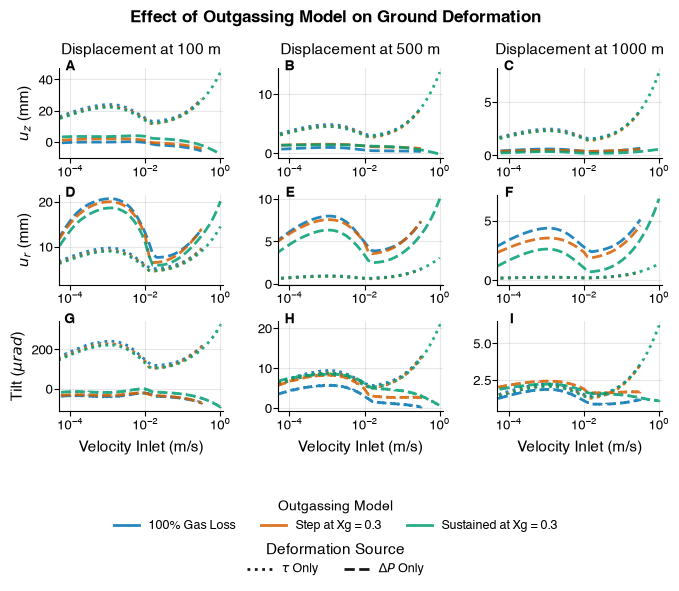

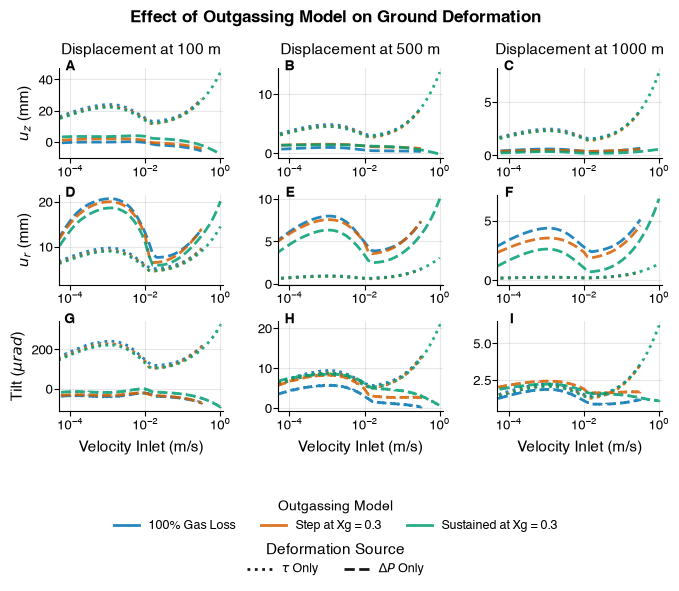

In [19]:
plot_conduit_analysis_fig2_with_ground_deformation_presentation(df, df_ge_test, colormap='batlow', figsize=(7, 5.5), save_plot=True)

In [20]:
def plot_combined_conduit_and_ground_deformation(
    df,
    df_ge,
    selected_velocities=(0.001, 0.1),
    figsize=(18, 13),
    save_plot=True,
    output_prefix='../../output_plots/3/figure2_combined_conduit_ground_deformation_june26'
):
    from matplotlib.ticker import MaxNLocator
    import matplotlib.pyplot as plt
    import matplotlib as mpl
    import numpy as np
    import pandas as pd
    import string

    mpl.rcParams.update({
        'font.family': 'sans-serif',
        'font.sans-serif': [
            'Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'
        ],
        'font.size': 11,
        'axes.labelsize': 11,
        'axes.titlesize': 11,
        'xtick.labelsize': 9.5,
        'ytick.labelsize': 9.5,
        'legend.fontsize': 10,
    })

    # ------------------------------------------------------------
    # Prepare data
    # ------------------------------------------------------------
    df_analysis = calculate_excess_pressure(df).copy()

    if 'Sb' in df_analysis.columns:
        df_analysis['1-Sb'] = 1 - df_analysis['Sb']

    color_list = ['#0072B2', '#D55E00', '#009E73']

    sb_labels = {
        0: '100% Gas Loss',
        4: 'Step at Xg = 0.3',
        6: 'Sustained at Xg = 0.3',
    }

    sb_options = [
        sb for sb in [0, 4, 6]
        if sb in df_analysis['Sb_option'].unique()
    ]

    sb_to_color = {
        sb: color_list[i]
        for i, sb in enumerate(sb_options)
    }

    sb_to_label = {
        sb: sb_labels.get(sb, f'Sb = {sb}')
        for sb in sb_options
    }

    # ------------------------------------------------------------
    # Maximum velocity from Sb = 0
    # ------------------------------------------------------------
    sb0_velocities = (
        df_analysis.loc[
            df_analysis['Sb_option'] == 0,
            'U_in'
        ]
        .dropna()
    )

    if sb0_velocities.empty:
        raise ValueError('No velocity data found for Sb_option == 0.')

    max_velocity_sb0 = sb0_velocities.max()

    # Only retain velocities within Sb = 0 range
    df_analysis = df_analysis[
        df_analysis['U_in'] <= max_velocity_sb0
    ].copy()

    df_ge_plot = df_ge[
        df_ge['U_in'] <= max_velocity_sb0
    ].copy()

    positive_velocities = pd.concat([
        df_analysis['U_in'],
        df_ge_plot['U_in']
    ]).dropna()

    positive_velocities = positive_velocities[
        positive_velocities > 0
    ]

    min_velocity = positive_velocities.min()

    # ------------------------------------------------------------
    # Plot definitions
    # ------------------------------------------------------------
    variables = {
        'Xg': r'$X_g$',
        'P_excess': r'$\Delta P$ (MPa)',
        'spf.mu*spf.sr': r'$\tau$ (MPa)',
    }

    distances = [100, 500, 1000]

    deformation_rows = [
        ('w2', r'$u_z$ (mm)'),
        ('u2', r'$u_r$ (mm)'),
        ('solid.RotrZ', r'Tilt ($\mu$rad)'),
    ]

    # ------------------------------------------------------------
    # GridSpec
    #
    # 6 columns total
    #
    # Row 0: inlet pressure spans all 6
    # Row 1: SIX depth-profile plots
    # Rows 2-4: ground deformation, 3 plots per row
    # ------------------------------------------------------------
    fig = plt.figure(figsize=figsize)

    gs = fig.add_gridspec(
    nrows=6,
    ncols=6,
    height_ratios=[
        0.9,   # inlet pressure
        0.2,  # spacer
        1.4,   # six conduit profiles
        1.0,   # vertical displacement
        1.0,   # radial displacement
        1.0,   # tilt
    ],
    hspace=0.3,
    wspace=0.35
    )
    # ============================================================
    # A. Inlet overpressure
    # ============================================================
    # inlet pressure
    ax_top = fig.add_subplot(gs[0, :])

  
    for sb in sb_options:

        df_sb = df_analysis[
            df_analysis['Sb_option'] == sb
        ]

        vel_plot = []
        p_plot = []

        for velocity in sorted(
            df_sb['U_in'].dropna().unique()
        ):

            df_vel = df_sb[
                df_sb['U_in'] == velocity
            ]

            if df_vel.empty:
                continue

            deepest_idx = df_vel['z'].idxmin()

            vel_plot.append(velocity)

            p_plot.append(
                df_vel.loc[
                    deepest_idx,
                    'P_excess'
                ] / 1e6
            )

        ax_top.semilogx(
            vel_plot,
            p_plot,
            color=sb_to_color[sb],
            linewidth=2.5,
            label=sb_to_label[sb]
        )

    for velocity in selected_velocities:
        ax_top.axvline(
            velocity,
            color='0.45',
            linestyle='--',
            linewidth=1,
            alpha=0.7
        )

    ax_top.set_xlim(
        min_velocity * 0.8,
        max_velocity_sb0 * 1.05
    )

    ax_top.set_xlabel('Inlet Velocity (m/s)')
    ax_top.set_ylabel(r'Inlet $\Delta P$ (MPa)')

    ax_top.grid(True, alpha=0.3)

    ax_top.spines['top'].set_visible(False)
    ax_top.spines['right'].set_visible(False)

    ax_top.legend(
        loc='upper left',
        fontsize=8,
        frameon=True,
        framealpha=0.9,
        borderpad=0.25,
        labelspacing=0.25,
        handlelength=1.5,
        handletextpad=0.4,
        borderaxespad=0.3,
        title='Outgassing Model',
        title_fontsize=8
    )
    # ============================================================
    # B-G. SIX depth-profile plots in ONE ROW
    #
    # Layout:
    #
    # velocity 1:
    # Xg | dP | tau
    #
    # velocity 2:
    # Xg | dP | tau
    #
    # All six occupy one GridSpec column each
    # ============================================================
    conduit_axes = []

    profile_number = 0

    for velocity in selected_velocities:

        for var, var_name in variables.items():

            # conduit profiles
            ax = fig.add_subplot(gs[2, profile_number])
        
                
            conduit_axes.append(ax)

            for sb in sb_options:

                data = df_analysis[
                    (
                        df_analysis['Sb_option'] == sb
                    )
                    &
                    np.isclose(
                        df_analysis['U_in'],
                        velocity
                    )
                ].sort_values('z')

                if data.empty or var not in data.columns:
                    continue

                if var in ['spf.mu*spf.sr', 'P_excess']:
                    x = data[var] / 1e6
                else:
                    x = data[var]

                ax.plot(
                    x,
                    data['z'] / 1e3,
                    color=sb_to_color[sb],
                    linewidth=2
                )

            # Formatting
            if var == 'Xg':
                ax.set_xticks([0, 0.3])

            elif var == 'spf.mu*spf.sr':
                # make x-axis log scale for tau
                ax.set_xscale('log')
                pass 
                # if np.isclose(velocity, 0.1):
                #     ax.set_xticks([0, 0.15])
                # else:
                #     ax.set_xticks([0, 2])

            else:
                ax.xaxis.set_major_locator(
                    MaxNLocator(nbins=3)
                )

            ax.xaxis.set_ticks_position('top')
            ax.xaxis.set_label_position('top')

            ax.set_xlabel(var_name, labelpad=4)

            # Only first plot of each velocity block gets depth label
            if var == 'Xg':
                ax.set_ylabel('Depth (km)')
            else:
                ax.tick_params(labelleft=False)

            ax.grid(True, alpha=0.3)

            ax.spines['bottom'].set_visible(False)
            ax.spines['right'].set_visible(False)

            # velocity annotation in bottom-right of each profile plot
            ax.text(
                0.95,
                0.05,
                f'{velocity:g} m/s',
                transform=ax.transAxes,
                ha='right',
                va='bottom',
                bbox=dict(
                    boxstyle='round,pad=0.25',
                    facecolor='0.95',
                    edgecolor='0.7',
                    linewidth=0.8,
                    alpha=0.9
                )
            )

            profile_number += 1

    # ============================================================
    # Ground deformation
    #
    # 3 plots per row, each spanning TWO GridSpec columns
    # ============================================================
    deformation_axes = []
    # deformation rows
            
    for row_offset, (disp_var, disp_name) in enumerate(
        deformation_rows
    ):

        gs_row = row_offset + 3 # deformation rows start at row 3

        for col_idx, r_from_cond in enumerate(
            distances
        ):

            col_start = col_idx * 2

            ax = fig.add_subplot(
                gs[
                    gs_row,
                    col_start:col_start + 2
                ]
            )

            deformation_axes.append(ax)

            for param_def in [0, 2]:

                for sb in sb_options:

                    mask = (
                        (
                            df_ge_plot['Sb_option'] == sb
                        )
                        &
                        (
                            df_ge_plot['r'] == r_from_cond
                        )
                    )

                    if 'param_def' in df_ge_plot.columns:
                        mask &= (
                            df_ge_plot['param_def'] == param_def
                        )

                    data = (
                        df_ge_plot.loc[mask]
                        .sort_values('U_in')
                    )

                    if (
                        data.empty
                        or disp_var not in data.columns
                    ):
                        continue

                    x = data['U_in'].to_numpy()

                    if disp_var == 'solid.RotrZ':
                        y = (
                            data[disp_var].to_numpy()
                            * 1e6
                        )
                    else:
                        y = (
                            data[disp_var].to_numpy()
                            * 1e3
                        )

                    linestyle = (
                        ':'
                        if param_def == 0
                        else '--'
                    )

                    ax.semilogx(
                        x,
                        y,
                        color=sb_to_color[sb],
                        linewidth=2,
                        linestyle=linestyle
                    )

            ax.set_xlim(
                min_velocity * 0.8,
                max_velocity_sb0 * 1.05
            )

            ax.grid(True, alpha=0.3)

            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)

            ax.xaxis.set_ticks_position('bottom')
            ax.xaxis.set_label_position('bottom')

            ax.tick_params(
                axis='x',
                which='both',
                top=False,
                labeltop=False,
                bottom=True,
                labelbottom=True
            )
            if row_offset == 0:
                ax.set_title(
                    f'{r_from_cond} m'
                )

            if col_idx == 0:
                ax.set_ylabel(
                    disp_name
                )
            else:
                pass
                # ax.tick_params(
                #     labelleft=False
                # )

            if row_offset == 2:
                ax.set_xlabel(
                    'Velocity Inlet (m/s)'
                )

    # ------------------------------------------------------------
    # Panel letters
    # ------------------------------------------------------------
    all_axes = (
        [ax_top]
        + conduit_axes
        + deformation_axes
    )

    for label, ax in zip(
        string.ascii_uppercase,
        all_axes
    ):
        ax.text(
            0.02,
            0.96,
            label,
            transform=ax.transAxes,
            fontsize=10,
            fontweight='bold',
            va='top',
            ha='left'
        )

    # ------------------------------------------------------------
    # Legends
    # ------------------------------------------------------------
    color_handles = [
        plt.Line2D(
            [0], [0],
            color=sb_to_color[sb],
            lw=2.5
        )
        for sb in sb_options
    ]

    color_labels = [
        sb_to_label[sb]
        for sb in sb_options
    ]

    style_handles = [
        plt.Line2D(
            [0], [0],
            color='k',
            lw=2,
            linestyle=':'
        ),
        plt.Line2D(
            [0], [0],
            color='k',
            lw=2,
            linestyle='--'
        ),
    ]

    fig.legend(
        color_handles,
        color_labels,
        ncol=3,
        loc='lower center',
        bbox_to_anchor=(0.5, 0.025),
        frameon=False,
        title='Outgassing Model'
    )

    fig.legend(
        style_handles,
        [
            r'$\tau$ Only',
            r'$\Delta P$ Only'
        ],
        ncol=2,
        loc='lower center',
        bbox_to_anchor=(0.5, -0.005),
        frameon=False,
        title='Deformation Source'
    )

    fig.subplots_adjust(
        left=0.065,
        right=0.985,
        top=0.97,
        bottom=0.11
    )

    # ------------------------------------------------------------
    # Save
    # ------------------------------------------------------------
    if save_plot:

        fig.savefig(
            output_prefix + '.png',
            dpi=300,
            bbox_inches='tight'
        )

        fig.savefig(
            output_prefix + '.pdf',
            dpi=300,
            bbox_inches='tight'
        )

        fig.savefig(
            output_prefix + '.svg',
            dpi=300,
            bbox_inches='tight'
        )

    return fig, max_velocity_sb0

Debug: z range: -3000.0 to 0.0
Debug: depth range: -0.0 to 3000.0
Debug: linproj_r range: 2209327.5037057796 to 114920000.0
Debug: P_excess range: -5408361.100000009 to 35459594.8
Max Sb=0 velocity used for all curves: 0.31623 m/s


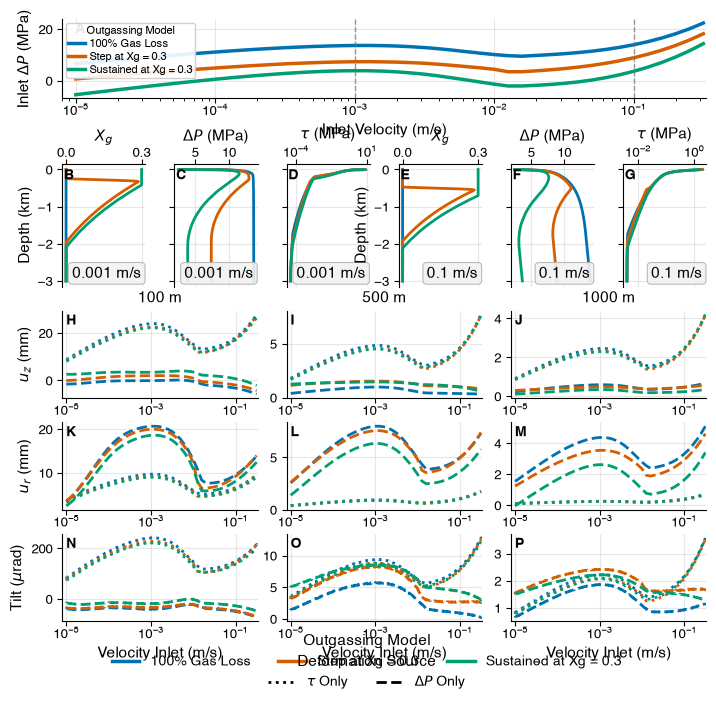

In [21]:
combined_fig, max_velocity_sb0 = plot_combined_conduit_and_ground_deformation(
    df,
    df_ge_test,
    selected_velocities=(0.001, 0.1),
    figsize=(7, 7),
    save_plot=True
)
print(f'Max Sb=0 velocity used for all curves: {max_velocity_sb0:g} m/s')

Debug: z range: -3000.0 to 0.0
Debug: depth range: -0.0 to 3000.0
Debug: linproj_r range: 2209327.5037057796 to 114920000.0
Debug: P_excess range: -5408361.100000009 to 35459594.8
Max Sb=0 velocity used for all curves: 0.31623 m/s


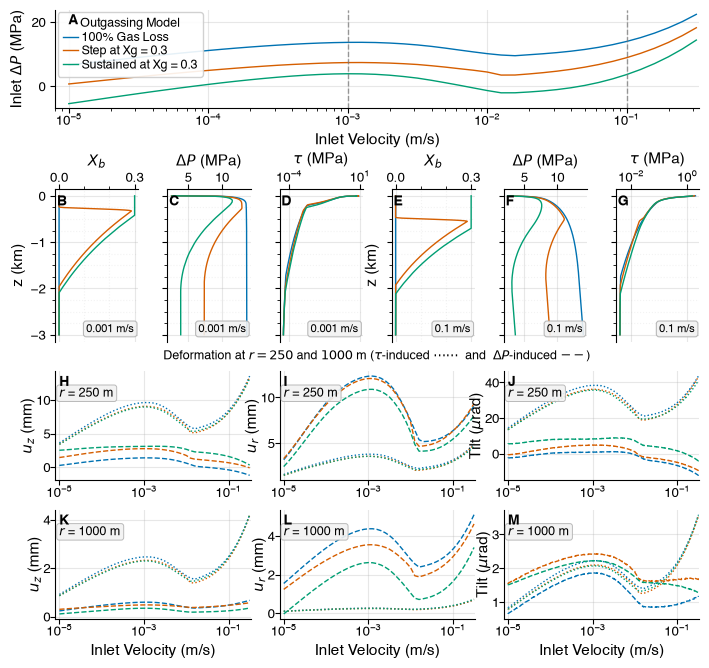

In [22]:
def plot_combined_conduit_and_ground_deformation(
    df,
    df_ge,
    selected_velocities=(0.001, 0.1),
    figsize=(18, 13),
    save_plot=True,
    output_prefix='../../output_plots/3/figure2_combined_conduit_ground_deformation_Aug26'
):
    from matplotlib.ticker import MaxNLocator
    import matplotlib.pyplot as plt
    import matplotlib as mpl
    import numpy as np
    import pandas as pd
    import string
    from matplotlib.ticker import MaxNLocator, MultipleLocator

    mpl.rcParams.update({
        'font.family': 'sans-serif',
        'font.sans-serif': [
            'Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'
        ],
        'font.size': 11,
        'axes.labelsize': 11,
        'axes.titlesize': 11,
        'xtick.labelsize': 9.5,
        'ytick.labelsize': 9.5,
        'legend.fontsize': 10,
    })

    # ------------------------------------------------------------
    # Prepare data
    # ------------------------------------------------------------
    df_analysis = calculate_excess_pressure(df).copy()

    if 'Sb' in df_analysis.columns:
        df_analysis['1-Sb'] = 1 - df_analysis['Sb']

    color_list = ['#0072B2', '#D55E00', '#009E73']

    sb_labels = {
        0: '100% Gas Loss',
        4: 'Step at Xg = 0.3',
        6: 'Sustained at Xg = 0.3',
    }

    sb_options = [
        sb for sb in [0, 4, 6]
        if sb in df_analysis['Sb_option'].unique()
    ]

    sb_to_color = {
        sb: color_list[i]
        for i, sb in enumerate(sb_options)
    }

    sb_to_label = {
        sb: sb_labels.get(sb, f'Sb = {sb}')
        for sb in sb_options
    }

    # ------------------------------------------------------------
    # Maximum velocity from Sb = 0
    # ------------------------------------------------------------
    sb0_velocities = (
        df_analysis.loc[
            df_analysis['Sb_option'] == 0,
            'U_in'
        ]
        .dropna()
    )

    if sb0_velocities.empty:
        raise ValueError('No velocity data found for Sb_option == 0.')

    max_velocity_sb0 = sb0_velocities.max()

    # Only retain velocities within the Sb = 0 velocity range
    df_analysis = df_analysis[
        df_analysis['U_in'] <= max_velocity_sb0
    ].copy()

    df_ge_plot = df_ge[
        df_ge['U_in'] <= max_velocity_sb0
    ].copy()

    positive_velocities = pd.concat([
        df_analysis['U_in'],
        df_ge_plot['U_in']
    ]).dropna()

    positive_velocities = positive_velocities[
        positive_velocities > 0
    ]

    min_velocity = positive_velocities.min()

    # ------------------------------------------------------------
    # Plot definitions
    # ------------------------------------------------------------
    variables = {
        'Xg': r'$X_b$',
        'P_excess': r'$\Delta P$ (MPa)',
        'spf.mu*spf.sr': r'$\tau$ (MPa)',
    }

    # Ground deformation rows are now distance
    distances = [250, 1000]

    # Ground deformation columns
    deformation_cols = [
        ('w2', r'$u_z$ (mm)'),
        ('u2', r'$u_r$ (mm)'),
        ('solid.RotrZ', r'Tilt ($\mu$rad)'),
    ]

    # ------------------------------------------------------------
    # GridSpec
    #
    # 6 columns total
    #
    # Row 0: inlet pressure
    # Row 1: spacer
    # Row 2: six conduit profiles
    # Row 3: deformation at 250 m
    # Row 4: deformation at 1000 m
    # ------------------------------------------------------------
    fig = plt.figure(figsize=figsize)

    gs = fig.add_gridspec(
        nrows=5,
        ncols=6,
        height_ratios=[
            0.9,   # inlet pressure
            0.2,   # spacer
            1.4,   # six conduit profiles
            1.0,   # deformation at 250 m
            1.0,   # deformation at 1000 m
        ],
        hspace=0.3,
        wspace=0.35
    )

    # ============================================================
    # A. Inlet overpressure
    # ============================================================
    ax_top = fig.add_subplot(gs[0, :])

    for sb in sb_options:

        df_sb = df_analysis[
            df_analysis['Sb_option'] == sb
        ]

        vel_plot = []
        p_plot = []

        for velocity in sorted(
            df_sb['U_in'].dropna().unique()
        ):

            df_vel = df_sb[
                df_sb['U_in'] == velocity
            ]

            if df_vel.empty:
                continue

            deepest_idx = df_vel['z'].idxmin()

            vel_plot.append(velocity)

            p_plot.append(
                df_vel.loc[
                    deepest_idx,
                    'P_excess'
                ] / 1e6
            )

        ax_top.semilogx(
            vel_plot,
            p_plot,
            color=sb_to_color[sb],
            linewidth=1,
            label=sb_to_label[sb]
        )

    # Mark selected conduit-profile velocities
    for velocity in selected_velocities:
        ax_top.axvline(
            velocity,
            color='0.45',
            linestyle='--',
            linewidth=1,
            alpha=0.7
        )

    ax_top.set_xlim(
        min_velocity * 0.8,
        max_velocity_sb0 * 1.05
    )

    ax_top.set_xlabel('Inlet Velocity (m/s)')
    ax_top.set_ylabel(r'Inlet $\Delta P$ (MPa)')

    ax_top.grid(True, alpha=0.3)

    ax_top.spines['top'].set_visible(False)
    ax_top.spines['right'].set_visible(False)

    # Compact outgassing-model legend
    ax_top.legend(
        loc='upper left',
        fontsize=9,
        frameon=True,
        framealpha=0.9,
        borderpad=0.4,
        labelspacing=0.15,
        handlelength=1.2,
        handletextpad=0.3,
        borderaxespad=0.2,
        title='Outgassing Model',
        title_fontsize=9
    )

    # ============================================================
    # B-G. SIX depth-profile plots in ONE ROW
    #
    # 0.001 m/s:
    # Xg | dP | tau
    #
    # 0.1 m/s:
    # Xg | dP | tau
    # ============================================================
    conduit_axes = []

    profile_number = 0

    for velocity in selected_velocities:

        for var, var_name in variables.items():

            ax = fig.add_subplot(
                gs[2, profile_number]
            )

            conduit_axes.append(ax)

            for sb in sb_options:

                data = df_analysis[
                    (
                        df_analysis['Sb_option'] == sb
                    )
                    &
                    np.isclose(
                        df_analysis['U_in'],
                        velocity
                    )
                ].sort_values('z')

                if data.empty or var not in data.columns:
                    continue

                if var in ['spf.mu*spf.sr', 'P_excess']:
                    x = data[var] / 1e6
                else:
                    x = data[var]

                ax.plot(
                    x,
                    data['z'] / 1e3,
                    color=sb_to_color[sb],
                    linewidth=1
                )

            # ----------------------------------------------------
            # Conduit x-axis formatting
            # ----------------------------------------------------
            if var == 'Xg':
                # Major ticks
                ax.set_xticks([0, 0.3])

                # Minor ticks every 0.1 Xg
                ax.xaxis.set_minor_locator(
                    MultipleLocator(0.1)
                )

                # Minor vertical grid lines
                ax.grid(
                    True,
                    which='minor',
                    axis='x',
                    alpha=0.15,
                    linestyle=':'
                )
            elif var == 'spf.mu*spf.sr':

                # Log scale for shear stress
                ax.set_xscale('log')

            else:

                ax.xaxis.set_major_locator(
                    MaxNLocator(nbins=3)
                )

            # x-axis at top for conduit profiles
            ax.xaxis.set_ticks_position('top')
            ax.xaxis.set_label_position('top')
            
            ax.set_xlabel(
                var_name,
                labelpad=4
            )

            # Keep depth labels for both Xg plots
            if var == 'Xg':
                ax.set_ylabel('z (km)')
            else:
                ax.tick_params(
                    axis='y',
                    labelleft=True
                )

            ax.grid(True, alpha=0.3)

            ax.spines['bottom'].set_visible(False)
            ax.spines['right'].set_visible(False)

            # ----------------------------------------------------
            # Velocity annotation in bottom-right
            # ----------------------------------------------------
            ax.text(
                0.95,
                0.05,
                f'{velocity:g} m/s',
                transform=ax.transAxes,
                ha='right',
                va='bottom',
                fontsize=8,
                bbox=dict(
                    boxstyle='round,pad=0.25',
                    facecolor='0.95',
                    edgecolor='0.7',
                    linewidth=0.8,
                    alpha=0.9
                )
            )
            ax.yaxis.set_minor_locator(MultipleLocator(0.25))

            # Grid
            ax.grid(
                True,
                which='major',
                alpha=0.3
            )

            ax.grid(
                True,
                which='minor',
                axis='y',
                alpha=0.15,
                linestyle=':'
            )
            # Major/minor depth ticks

            profile_number += 1
    # set every column besides first to have no y tick labels 
    for ax in conduit_axes[1:]:
        ax.tick_params(
            axis='y',
            labelleft=False
        )

    # ============================================================
    # Ground deformation
    #
    # ROWS = distance from conduit:
    #   Row 3 = 250 m
    #   Row 4 = 1000 m
    #
    # COLUMNS:
    #   vertical displacement | radial displacement | tilt
    # ============================================================
    deformation_axes = []

    for row_offset, r_from_cond in enumerate(distances):

        gs_row = row_offset + 3

        for col_idx, (disp_var, disp_name) in enumerate(
            deformation_cols
        ):

            # Each deformation plot spans two GridSpec columns
            col_start = col_idx * 2

            ax = fig.add_subplot(
                gs[
                    gs_row,
                    col_start:col_start + 2
                ]
            )

            deformation_axes.append(ax)

            for param_def in [0, 2]:

                for sb in sb_options:

                    mask = (
                        (
                            df_ge_plot['Sb_option'] == sb
                        )
                        &
                        (
                            df_ge_plot['r'] == r_from_cond
                        )
                    )

                    if 'param_def' in df_ge_plot.columns:
                        mask &= (
                            df_ge_plot['param_def']
                            == param_def
                        )

                    data = (
                        df_ge_plot.loc[mask]
                        .sort_values('U_in')
                    )

                    if (
                        data.empty
                        or disp_var not in data.columns
                    ):
                        continue

                    x = data['U_in'].to_numpy()

                    if disp_var == 'solid.RotrZ':

                        # rad -> microradians
                        y = (
                            data[disp_var].to_numpy()
                            * 1e6
                        )

                    else:

                        # m -> mm
                        y = (
                            data[disp_var].to_numpy()
                            * 1e3
                        )

                    linestyle = (
                        ':'
                        if param_def == 0
                        else '--'
                    )

                    ax.semilogx(
                        x,
                        y,
                        color=sb_to_color[sb],
                        linewidth=1,
                        linestyle=linestyle
                    )

            # ----------------------------------------------------
            # Deformation formatting
            # ----------------------------------------------------
            ax.set_xlim(
                min_velocity * 0.8,
                max_velocity_sb0 * 1.05
            )

            ax.grid(True, alpha=0.3)

            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)

            # Explicitly keep x ticks on bottom only
            ax.xaxis.set_ticks_position('bottom')
            ax.xaxis.set_label_position('bottom')

            ax.tick_params(
                axis='x',
                which='both',
                top=False,
                labeltop=False,
                bottom=True,
                labelbottom=True
            )

            # Keep y tick labels on EVERY deformation panel
            ax.tick_params(
                axis='y',
                which='both',
                left=True,
                labelleft=True
            )

            # ----------------------------------------------------
            # Column headings = deformation quantity
            # ----------------------------------------------------
            # if row_offset == 0:
            #     ax.set_title(
            #         disp_name,
            #         pad=6
            #     )
            
            ax.set_ylabel(
                    disp_name,labelpad=0)
            # move yticklabels closer to y-axis
            ax.tick_params(
                axis='y',
                which='major',
                pad=0.05
            )
            # ----------------------------------------------------
            # Distance label in first panel of each row
            # ----------------------------------------------------
            # if col_idx == 0:

            ax.text(
                0.02,
                0.85,
                f'$r$ = {r_from_cond} m',
                transform=ax.transAxes,
                ha='left',
                va='top',
                fontsize=9,
                bbox=dict(
                    boxstyle='round,pad=0.2',
                    facecolor='0.95',
                    edgecolor='0.7',
                    linewidth=0.7,
                    alpha=0.9
                )
            )
            if row_offset == 0 and col_idx == 1:
                ax.set_title(
                    r'Deformation at $r = 250$ and $1000$ m ' +
                 
                    r'($\tau$-induced $\cdots\cdots$  and  $\Delta P$-induced $--$)',
                    pad=8,
                    fontsize=9
                )

            # Only bottom deformation row gets x-axis title
            if row_offset == len(distances) - 1:

                ax.set_xlabel(
                    'Inlet Velocity (m/s)'
                )

    # ------------------------------------------------------------
    # Panel letters
    # ------------------------------------------------------------
    all_axes = (
        [ax_top]
        + conduit_axes
        + deformation_axes
    )

    for label, ax in zip(
        string.ascii_uppercase,
        all_axes
    ):

        ax.text(
            0.02,
            0.96,
            label,
            transform=ax.transAxes,
            fontsize=10,
            fontweight='bold',
            va='top',
            ha='left',
            zorder=100
        )

    # ------------------------------------------------------------
    # Deformation-source legend
    # ------------------------------------------------------------
    style_handles = [
        plt.Line2D(
            [0], [0],
            color='k',
            lw=2,
            linestyle=':'
        ),
        plt.Line2D(
            [0], [0],
            color='k',
            lw=2,
            linestyle='--'
        ),
    ]

    # fig.legend(
    #     style_handles,
    #     [
    #         r'$\tau$ Only',
    #         r'$\Delta P$ Only'
    #     ],
    #     ncol=2,
    #     loc='lower center',
    #     bbox_to_anchor=(0.5, 0.025),
    #     frameon=False,
    #     title='Deformation Source'
    # )

    # ------------------------------------------------------------
    # Figure spacing
    # ------------------------------------------------------------
    fig.subplots_adjust(
        left=0.065,
        right=0.985,
        top=0.97,
        bottom=0.10
    )

    # ------------------------------------------------------------
    # Save
    # ------------------------------------------------------------
    if save_plot:

        fig.savefig(
            output_prefix + '.png',
            dpi=300,
            bbox_inches='tight'
        )

        fig.savefig(
            output_prefix + '.pdf',
            dpi=300,
            bbox_inches='tight'
        )

        fig.savefig(
            output_prefix + '.svg',
            dpi=300,
            bbox_inches='tight'
        )

    return fig, max_velocity_sb0


combined_fig, max_velocity_sb0 = plot_combined_conduit_and_ground_deformation(
    df,
    df_ge_test,
    selected_velocities=(0.001, 0.1),
    figsize=(7, 7),
    save_plot=True
)
print(f'Max Sb=0 velocity used for all curves: {max_velocity_sb0:g} m/s')